<a href="https://colab.research.google.com/github/arielsharonferdinandus/Transboundary-Haze-Forecasting/blob/new-data-and-refactor/Transboundary_Haze_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transboundary Haze Forecasting: Predicting PM2.5 Spikes in Singapore
**Theme:** Energy & Environment (Air Quality) | **Type:** Time-Series Forecasting | **Data:** Marine Terrace sensor (Apr-Sep 2026) + Marina Barrage daily weather

**This notebook**
- **Part 1:** problem formulation, data audit, cleaning, EDA (Phases 1-2)
- **Part 2:** feature engineering, forecast targets, leakage tests, chronological split (Phase 3)
- **Part 3:** baselines, SARIMAX, Holt-Winters, LightGBM, Ridge, evaluated on validation and test (Phase 4), followed by a **Limitations** section
- *Parts 4+ (tuning, interpretation, recommendations) will be appended next.*

**How to run on Colab:** Runtime > Run all. When the data cell asks for files, upload all 6 monthly Marine Terrace CSVs
(`openaq_location_6301631_measurments_<month>.csv`) and all 6 weather CSVs (`DAILYDATA_S108_<yyyymm>.csv`) together. Nothing else needs uploading.

# Part 1: Problem Formulation, Data Audit and EDA (Phases 1-2)

**Stakeholder:** National Environment Agency (NEA) Singapore / Director of Public Health.

**Predictive question:** Can historical PM2.5 and weather data forecast PM2.5 spikes 24-48 hours ahead during regional haze (Indonesian land and forest fire) episodes?

**Target:** `pm25` (ug/m3), hourly. **Unit of analysis:** hourly timestamp at the Marine Terrace sensor.

**Data used**
- *Air quality:* OpenAQ / AirGradient sensor at **Marine Terrace** (location 6301631), hourly PM1, PM2.5, humidity, temperature and particle count (um003), 9 Apr - 30 Sep 2026, six monthly exports.
- *Weather:* **Marina Barrage** (station S108) daily rainfall and wind speed, Apr - Sep 2026. Daily temperature columns in this export are empty, and there is no wind direction.

> Scope note: the models *predict haze arrival from observed signals*. They do not simulate fire ignition and make no causal claims about fires.

## Part 1 · 0. Setup

In [ ]:
!pip -q install pandas numpy matplotlib seaborn
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 4.5)
H = pd.Timedelta(hours=1)

## Part 1 · 1. Load the data
Put the CSVs in a `data/` folder: the monthly Marine Terrace exports (`openaq_location_6301631_measurments_<month>.csv`) and the monthly weather files (`DAILYDATA_S108_<yyyymm>.csv`). On Colab, if they are not found, the cell opens an upload dialog (select all of them at once).

In [ ]:
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
PM_PATTERN = os.path.join(DATA_DIR, "openaq_location_6301631_measurments_*.csv")
WX_PATTERN = os.path.join(DATA_DIR, "DAILYDATA_S108_*.csv")

if not (glob.glob(PM_PATTERN) and glob.glob(WX_PATTERN)):
    try:
        from google.colab import files
        print("Upload ALL monthly Marine Terrace OpenAQ CSVs and ALL DAILYDATA_S108 weather CSVs")
        up = files.upload()
        for name, content in up.items():
            with open(os.path.join(DATA_DIR, name), "wb") as f:
                f.write(content)
    except ImportError:
        print("Not on Colab: copy the CSVs into ./data manually.")

pm_files, wx_files = sorted(glob.glob(PM_PATTERN)), sorted(glob.glob(WX_PATTERN))
print(len(pm_files), "air-quality files |", len(wx_files), "weather files")
assert pm_files and wx_files, "Missing input files"

raw = pd.concat([pd.read_csv(f).assign(source_file=os.path.basename(f)) for f in pm_files], ignore_index=True)
assert raw["location_id"].nunique() == 1, "Expected a single sensor location"
print("Sensor:", raw["location_name"].iloc[0].strip(), "| lat/lon:", round(raw["latitude"].iloc[0], 4), round(raw["longitude"].iloc[0], 4), "| provider:", raw["provider"].iloc[0])
print("Units:", raw.groupby("parameter")["unit"].first().to_dict())
display(raw.groupby("source_file").size().to_frame("rows"))
raw.head(3)

6 air-quality files | 9 weather files
Sensor: Marine Terrace | lat/lon: 1.2967 103.9186 | provider: AirGradient
Units: {'pm1': 'µg/m³', 'pm25': 'µg/m³', 'relativehumidity': '%', 'temperature': 'c', 'um003': 'particles/cm³'}


,rows
source_file,
openaq_location_6301631_measurments_april.csv,2280
openaq_location_6301631_measurments_august.csv,3580
openaq_location_6301631_measurments_july.csv,3600
openaq_location_6301631_measurments_june.csv,3480
openaq_location_6301631_measurments_may.csv,1850
openaq_location_6301631_measurments_september.csv,3480


,location_id,location_name,parameter,value,unit,datetimeUtc,datetimeLocal,timezone,latitude,longitude,country_iso,isMobile,isMonitor,owner_name,provider,source_file
0,6301631,Marine Terrace,pm1,7.0,µg/m³,2026-04-09T11:00:00Z,2026-04-09T19:00:00+08:00,Asia/Singapore,1.296704,103.918619,NaN,NaN,NaN,Matt Ranostay,AirGradient,openaq_location_6301631_measurments_april.csv
1,6301631,Marine Terrace,pm1,5.6,µg/m³,2026-04-09T12:00:00Z,2026-04-09T20:00:00+08:00,Asia/Singapore,1.296704,103.918619,NaN,NaN,NaN,Matt Ranostay,AirGradient,openaq_location_6301631_measurments_april.csv
2,6301631,Marine Terrace,pm1,8.7,µg/m³,2026-04-09T13:00:00Z,2026-04-09T21:00:00+08:00,Asia/Singapore,1.296704,103.918619,NaN,NaN,NaN,Matt Ranostay,AirGradient,openaq_location_6301631_measurments_april.csv


## Part 1 · 2. Air-quality audit (raw)
Checks: missing values, duplicates, invalid values (negative PM, exact zeros, humidity outside 0-100%, implausible temperature), sampling interval and gaps.

In [ ]:
ts = pd.to_datetime(raw["datetimeLocal"], errors="coerce")
if getattr(ts.dt, "tz", None) is not None:
    ts = ts.dt.tz_localize(None)                 # keep Singapore wall-clock time (+08:00 dropped)
raw["time"] = ts
raw["value"] = pd.to_numeric(raw["value"], errors="coerce")

display(pd.DataFrame({"null_time": [raw["time"].isna().sum()], "null_value": [raw["value"].isna().sum()],
                      "duplicate (time, parameter)": [raw.duplicated(["time", "parameter"]).sum()]}))
print("Coverage:", raw["time"].min(), "->", raw["time"].max())
display(raw.groupby("parameter")["value"].describe().round(2))

P_ = raw["parameter"]
invalid = {
    "negative PM1 / PM2.5 / um003":             int(((P_.isin(["pm1", "pm25", "um003"])) & (raw.value < 0)).sum()),
    "exact zero PM2.5 (sensor dropout)":         int(((P_ == "pm25") & (raw.value == 0)).sum()),
    "exact zero PM1":                            int(((P_ == "pm1") & (raw.value == 0)).sum()),
    "humidity outside 0-100":                    int(((P_ == "relativehumidity") & ~raw.value.between(0, 100)).sum()),
    "temperature outside 15-45 C":               int(((P_ == "temperature") & ~raw.value.between(15, 45)).sum()),
}
pv = raw.pivot_table(index="time", columns="parameter", values="value")
invalid["PM2.5 < PM1 (physically inconsistent)"] = int((pv["pm25"] < pv["pm1"]).sum())
print("Invalid / suspicious counts:")
for k, v in invalid.items(): print(f"  {k:45s} {v}")

,null_time,null_value,"duplicate (time, parameter)"
0,0,0,0


Coverage: 2026-04-09 19:00:00 -> 2026-09-30 08:00:00


,count,mean,std,min,25%,50%,75%,max
parameter,,,,,,,,
pm1,3654.0,15.77,13.15,0.0,5.40,14.4,23.4,178.6
pm25,3654.0,26.35,22.18,0.0,10.52,24.5,36.0,431.1
relativehumidity,3654.0,54.54,4.01,38.0,53.00,55.0,57.0,82.0
temperature,3654.0,29.74,1.29,24.3,29.50,30.2,30.5,32.0
um003,3654.0,1061.19,870.23,52.0,530.00,852.5,1343.5,14282.0


Invalid / suspicious counts:
  negative PM1 / PM2.5 / um003                  0
  exact zero PM2.5 (sensor dropout)             24
  exact zero PM1                                97
  humidity outside 0-100                        0
  temperature outside 15-45 C                   0
  PM2.5 < PM1 (physically inconsistent)         0


In [ ]:
# Sampling interval and gaps (PM2.5)
pmr = raw[raw.parameter == "pm25"].drop_duplicates("time").sort_values("time")
gap = pmr["time"].diff()
print("Intervals between consecutive PM2.5 readings:")
display(gap.value_counts().sort_index().to_frame("count"))
big = gap > H
gaps = pd.DataFrame({"last_reading_before_gap": pmr["time"].shift(1)[big], "next_reading": pmr["time"][big],
                     "missing_hours": (gap[big] / H - 1).astype(int)}).reset_index(drop=True)
print(f"{len(gaps)} gaps (more than 1 h missing); total missing hours = {gaps['missing_hours'].sum()}")
display(gaps)

Intervals between consecutive PM2.5 readings:


,count
time,
0 days 01:00:00,3642
0 days 02:00:00,4
0 days 03:00:00,1
0 days 04:00:00,1
1 days 01:00:00,4
17 days 00:00:00,1


11 gaps (more than 1 h missing); total missing hours = 512


,last_reading_before_gap,next_reading,missing_hours
0,2026-04-16 14:00:00,2026-04-16 17:00:00,2
1,2026-04-18 14:00:00,2026-04-18 16:00:00,1
2,2026-04-24 12:00:00,2026-04-24 14:00:00,1
3,2026-04-28 22:00:00,2026-05-15 22:00:00,407
4,2026-05-16 16:00:00,2026-05-16 18:00:00,1
5,2026-05-31 08:00:00,2026-06-01 09:00:00,24
6,2026-06-30 08:00:00,2026-07-01 09:00:00,24
7,2026-07-31 08:00:00,2026-08-01 09:00:00,24
8,2026-08-17 11:00:00,2026-08-17 15:00:00,3
9,2026-08-20 12:00:00,2026-08-20 14:00:00,1


**Reading the gaps.** The long gap (mid-May to 1 June) is a real sensor outage: it is already present in the earliest export. The five gaps of about 24 hours sit at month boundaries and look like an export date-range artifact (the last UTC day of each month is not in the file), so they could be recovered by re-exporting with the end date set to the 1st of the next month. They are not repaired here: no invented data.

## Part 1 · 3. Weather audit (Marina Barrage, daily)
Daily values: rainfall total, heaviest 30/60/120-minute rainfall, temperature (mean / max / min), mean wind speed and max wind speed. A `-` means not recorded.

In [ ]:
wx = pd.concat([pd.read_csv(f, skipinitialspace=True) for f in wx_files], ignore_index=True)
wx.columns = [c.strip() for c in wx.columns]
wx["date"] = pd.to_datetime(dict(year=wx["Year"], month=wx["Month"], day=wx["Day"]))
num_cols = [c for c in wx.columns if c not in ("Station", "Year", "Month", "Day", "date")]
for c in num_cols:
    wx[c] = pd.to_numeric(wx[c].astype(str).str.strip(), errors="coerce")      # "-" becomes NaN

print("Station:", wx["Station"].iloc[0], "|", wx["date"].min().date(), "->", wx["date"].max().date(), "|", len(wx), "days")
exp_days = pd.date_range(wx["date"].min(), wx["date"].max(), freq="D")
print("Missing calendar days:", len(exp_days.difference(wx["date"])), "| duplicate days:", int(wx["date"].duplicated().sum()))
miss = wx[num_cols].isna().mean().mul(100).round(1).to_frame("missing_%")
display(miss)
empty = list(miss.index[miss["missing_%"] == 100])
print("Columns with no data at all (dropped):", empty)

daily = wx.set_index("date").sort_index()[["Daily Rainfall Total (mm)", "Highest 60 min Rainfall (mm)",
                                            "Mean Wind Speed (km/h)", "Max Wind Speed (km/h)"]]
daily.columns = ["rain_mm", "rain_max60_mm", "wind_mean_kmh", "wind_max_kmh"]
assert daily.notna().all().all() and daily.index.is_unique
display(daily.describe().round(1).T)

Station: Marina Barrage | 2026-01-01 -> 2026-09-30 | 273 days
Missing calendar days: 0 | duplicate days: 0


,missing_%
Daily Rainfall Total (mm),0.0
Highest 30 min Rainfall (mm),0.0
Highest 60 min Rainfall (mm),0.0
Highest 120 min Rainfall (mm),0.0
Mean Temperature (°C),100.0
Maximum Temperature (°C),100.0
Minimum Temperature (°C),100.0
Mean Wind Speed (km/h),0.0
Max Wind Speed (km/h),0.0


Columns with no data at all (dropped): ['Mean Temperature (°C)', 'Maximum Temperature (°C)', 'Minimum Temperature (°C)']


,count,mean,std,min,25%,50%,75%,max
rain_mm,273.0,4.5,11.2,0.0,0.0,0.0,2.2,65.8
rain_max60_mm,273.0,3.5,8.4,0.0,0.0,0.0,1.4,51.0
wind_mean_kmh,273.0,6.9,3.3,2.7,4.5,5.7,9.0,17.4
wind_max_kmh,273.0,28.4,7.4,13.5,22.5,27.7,33.3,50.5


## Part 1 · 4. Cleaning, hourly grid and missing-value policy
1. Invalid values become NaN: exact-zero PM1 / PM2.5 (sensor dropouts, not real air), negative values, humidity outside 0-100, implausible temperature.
2. Everything is averaged to a regular **hourly** grid (this also removes any duplicate timestamps).
3. **Forward-fill for at most 6 hours** (uses the past only, so it cannot leak future information). Longer gaps stay NaN, and rows that need them are dropped later instead of inventing data. No mean / median imputation.

In [ ]:
clean = raw.dropna(subset=["time", "value"]).copy()
bad = (
    (clean.parameter.isin(["pm1", "pm25", "um003"]) & (clean.value < 0)) |
    (clean.parameter.isin(["pm1", "pm25"]) & (clean.value == 0)) |
    ((clean.parameter == "relativehumidity") & ~clean.value.between(0, 100)) |
    ((clean.parameter == "temperature") & ~clean.value.between(15, 45))
)
n_invalid = int(bad.sum())
print("Rows set to NaN as invalid:", n_invalid)
clean.loc[bad, "value"] = np.nan
clean["hour"] = clean["time"].dt.floor("h")

wide = clean.pivot_table(index="hour", columns="parameter", values="value", aggfunc="mean")
wide = wide.rename(columns={"relativehumidity": "rh", "temperature": "temp"})[["pm25", "pm1", "um003", "temp", "rh"]]
full_idx = pd.date_range(wide.index.min(), wide.index.max(), freq="h")
wide = wide.reindex(full_idx); wide.index.name = "datetime"

hourly = wide.ffill(limit=6)
for c in wide.columns:                         # never extend a series beyond its last real reading
    last = wide[c].last_valid_index()
    hourly.loc[hourly.index > last, c] = np.nan
hourly.index.freq = "h"

print(f"Hourly grid: {len(hourly)} hours, {hourly.index.min()} -> {hourly.index.max()}")
print(f"PM2.5 hours: observed {int(wide.pm25.notna().sum())}, after forward-fill {int(hourly.pm25.notna().sum())}, still missing {int(hourly.pm25.isna().sum())}")
nan_run = hourly["pm25"].isna().astype(int)
runs = nan_run.groupby((nan_run != nan_run.shift()).cumsum()).agg(["first", "size"])
runs = runs[runs["first"] == 1]["size"]
print("Remaining PM2.5 gaps (hours):", sorted(runs.tolist(), reverse=True))
hourly.describe().round(1).T

Rows set to NaN as invalid: 121
Hourly grid: 4166 hours, 2026-04-09 19:00:00 -> 2026-09-30 08:00:00
PM2.5 hours: observed 3630, after forward-fill 3693, still missing 473
Remaining PM2.5 gaps (hours): [401, 18, 18, 18, 18]


,count,mean,std,min,25%,50%,75%,max
parameter,,,,,,,,
pm25,3693.0,26.2,22.1,0.1,10.3,24.3,35.9,431.1
pm1,3693.0,15.7,13.1,0.1,5.4,14.1,23.3,178.6
um003,3693.0,1055.6,867.6,52.0,526.0,846.0,1338.0,14282.0
temp,3693.0,29.7,1.3,24.3,29.5,30.2,30.5,32.0
rh,3693.0,54.6,4.0,38.0,53.0,55.0,57.0,82.0


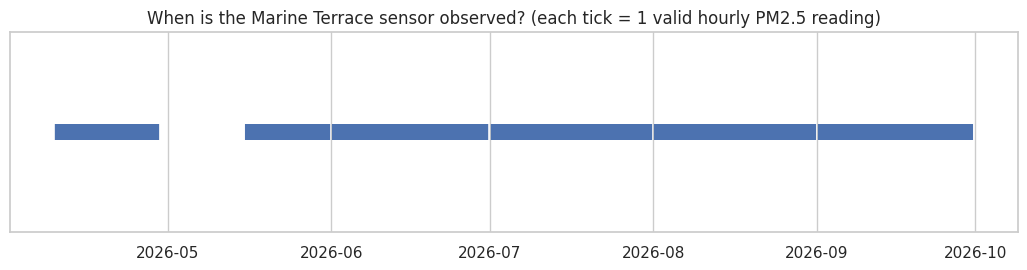

In [ ]:
fig, ax = plt.subplots(figsize=(13, 2.6))
obs = hourly["pm25"].dropna().index
ax.scatter(obs, np.zeros(len(obs)), marker="|", s=120)
ax.set_yticks([]); ax.set_title("When is the Marine Terrace sensor observed? (each tick = 1 valid hourly PM2.5 reading)")
plt.show()

## Part 1 · 5. EDA: air quality

In [ ]:
g = hourly["pm25"].groupby(hourly.index.to_period("M"))
monthly = pd.DataFrame({"observed_hours": g.count(), "mean": g.mean(), "p95": g.quantile(0.95), "max": g.max(),
                        "pct_hours_above_55": g.apply(lambda s: (s.dropna() > 55).mean() * 100),
                        "hours_above_150": g.apply(lambda s: int((s > 150).sum()))}).round(1)
print("PM2.5 by month (NEA 1-hour bands: Normal <=55, Elevated 56-150, High 151-250, Very High >250 ug/m3)")
display(monthly)
tot = hourly["pm25"].dropna()
print(f"Overall: mean {tot.mean():.1f}, median {tot.median():.1f}, max {tot.max():.1f} ug/m3 | "
      f"{(tot > 55).mean()*100:.1f}% of hours above 55, {int((tot > 150).sum())} hours above 150, {int((tot > 250).sum())} above 250")

PM2.5 by month (NEA 1-hour bands: Normal <=55, Elevated 56-150, High 151-250, Very High >250 ug/m3)


,observed_hours,mean,p95,max,pct_hours_above_55,hours_above_150
datetime,,,,,,
2026-04,466,14.5,31.2,160.2,0.9,1
2026-05,377,19.2,41.5,292.6,2.1,2
2026-06,702,12.6,33.1,213.8,1.1,1
2026-07,726,23.6,39.1,140.4,0.6,0
2026-08,726,32.7,48.4,130.6,2.2,0
2026-09,696,47.6,95.9,431.1,22.4,6


Overall: mean 26.2, median 24.3, max 431.1 ug/m3 | 5.3% of hours above 55, 10 hours above 150, 2 above 250


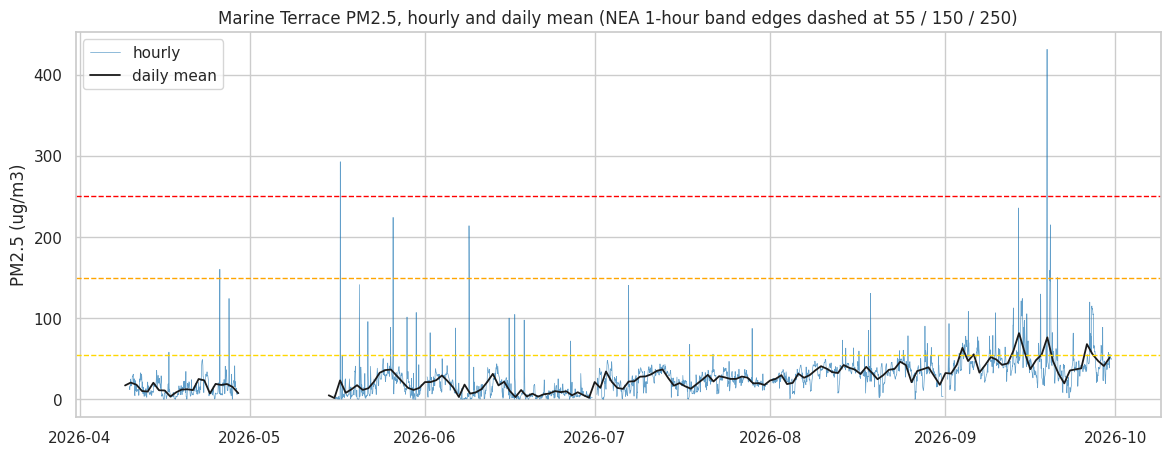

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(hourly.index, hourly["pm25"], lw=0.5, color="tab:blue", alpha=0.7, label="hourly")
ax.plot(hourly["pm25"].resample("D").mean().index, hourly["pm25"].resample("D").mean(), color="k", lw=1.3, label="daily mean")
for b, col in zip([55, 150, 250], ["gold", "orange", "red"]):
    ax.axhline(b, color=col, ls="--", lw=1)
ax.set_ylabel("PM2.5 (ug/m3)"); ax.set_title("Marine Terrace PM2.5, hourly and daily mean (NEA 1-hour band edges dashed at 55 / 150 / 250)")
ax.legend(loc="upper left"); plt.show()

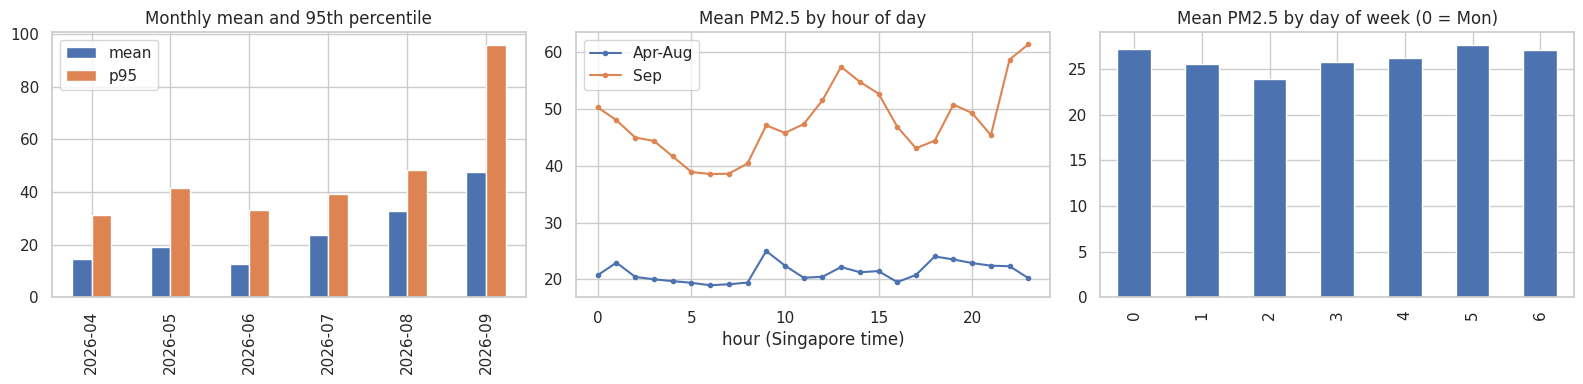

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
monthly[["mean", "p95"]].plot.bar(ax=axes[0]); axes[0].set_title("Monthly mean and 95th percentile"); axes[0].set_xlabel("")
d_ = hourly["pm25"]
early, late = d_[d_.index < "2026-09-01"], d_[d_.index >= "2026-09-01"]
early.groupby(early.index.hour).mean().plot(ax=axes[1], marker="o", ms=3, label="Apr-Aug")
late.groupby(late.index.hour).mean().plot(ax=axes[1], marker="o", ms=3, label="Sep")
axes[1].set_title("Mean PM2.5 by hour of day"); axes[1].legend(); axes[1].set_xlabel("hour (Singapore time)")
d_.groupby(d_.index.dayofweek).mean().plot.bar(ax=axes[2]); axes[2].set_title("Mean PM2.5 by day of week (0 = Mon)"); axes[2].set_xlabel("")
plt.tight_layout(); plt.show()

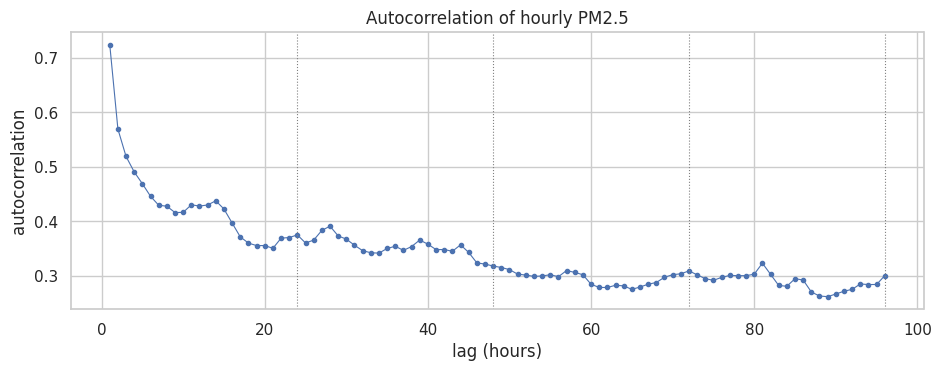

{'lag 1h': 0.724, 'lag 3h': 0.519, 'lag 6h': 0.446, 'lag 12h': 0.428, 'lag 24h': 0.375, 'lag 48h': 0.318, 'lag 72h': 0.309}


In [ ]:
# Persistence: autocorrelation of hourly PM2.5
acf = pd.Series({k: hourly["pm25"].autocorr(k) for k in range(1, 97)})
ax = acf.plot(marker="o", ms=3, lw=0.8, figsize=(11, 3.6))
for k in (24, 48, 72, 96): ax.axvline(k, color="grey", ls=":", lw=0.8)
ax.set_xlabel("lag (hours)"); ax.set_ylabel("autocorrelation"); ax.set_title("Autocorrelation of hourly PM2.5"); plt.show()
print({f"lag {k}h": round(float(acf[k]), 3) for k in (1, 3, 6, 12, 24, 48, 72)})

In [ ]:
# Episodes above the NEA 'Elevated' edge (55 ug/m3) and all hours above 150
ev = hourly["pm25"] > 55
grp = (ev != ev.shift()).cumsum()
ep = hourly[ev].groupby(grp[ev])["pm25"].agg(start=lambda s: s.index.min(), end=lambda s: s.index.max(), peak="max", mean="mean")
ep["hours"] = ((ep["end"] - ep["start"]) / H + 1).astype(int)
print(f"{len(ep)} episodes above 55 ug/m3 (consecutive hours); the 10 longest:")
display(ep.sort_values("hours", ascending=False).head(10).round(1).reset_index(drop=True))
hi = hourly.loc[hourly["pm25"] > 150, ["pm25", "pm1", "um003", "rh"]].round(1)
print(f"{len(hi)} hours above 150 ug/m3:"); display(hi)

74 episodes above 55 ug/m3 (consecutive hours); the 10 longest:


,start,end,peak,mean,hours
0,2026-09-26 12:00:00,2026-09-27 11:00:00,119.8,83.8,24
1,2026-09-04 11:00:00,2026-09-04 22:00:00,77.8,67.6,12
2,2026-09-14 05:00:00,2026-09-14 16:00:00,124.2,100.9,12
3,2026-09-14 18:00:00,2026-09-15 04:00:00,97.4,73.7,11
4,2026-09-06 11:00:00,2026-09-06 17:00:00,77.0,64.6,7
5,2026-09-19 09:00:00,2026-09-19 15:00:00,214.9,133.2,7
6,2026-09-03 22:00:00,2026-09-04 03:00:00,69.4,62.3,6
7,2026-09-06 19:00:00,2026-09-06 23:00:00,72.1,64.4,5
8,2026-09-08 18:00:00,2026-09-08 22:00:00,78.0,62.8,5
9,2026-09-28 12:00:00,2026-09-28 16:00:00,66.6,61.4,5


10 hours above 150 ug/m3:


parameter,pm25,pm1,um003,rh
datetime,,,,
2026-04-25 18:00:00,160.2,100.6,7488.0,50.0
2026-05-17 01:00:00,292.6,171.8,12460.0,61.0
2026-05-26 09:00:00,224.1,135.4,9857.0,58.0
2026-06-08 19:00:00,213.8,117.2,8885.0,58.0
2026-09-13 22:00:00,235.7,101.7,7916.0,50.0
2026-09-18 22:00:00,206.4,70.8,5930.0,53.0
2026-09-18 23:00:00,431.1,178.6,14282.0,54.0
2026-09-19 11:00:00,159.0,84.1,6280.0,59.0
2026-09-19 13:00:00,214.9,110.2,8324.0,55.0


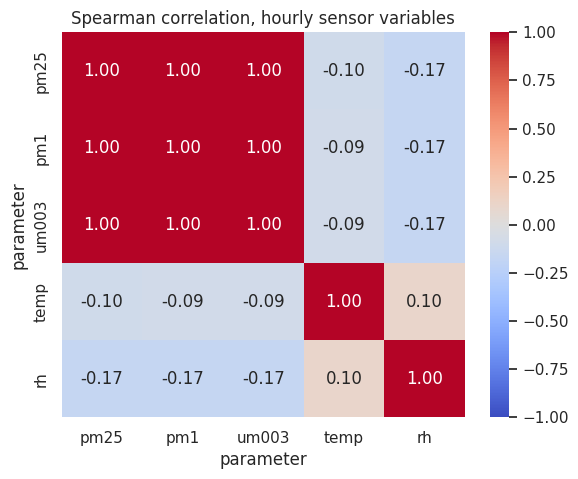

In [ ]:
# Composition and sensor weather: hourly correlations
cols = ["pm25", "pm1", "um003", "temp", "rh"]
plt.figure(figsize=(6.5, 5))
sns.heatmap(hourly[cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation, hourly sensor variables"); plt.show()

## Part 1 · 6. EDA: weather (Marina Barrage daily) vs PM2.5
A day's weather is only known after the day ends, so for the forecasting features (Part 2) only **previous complete days** will be used. Here the exploration looks at same-day and previous-day links, using days with at least 18 hourly PM2.5 readings.

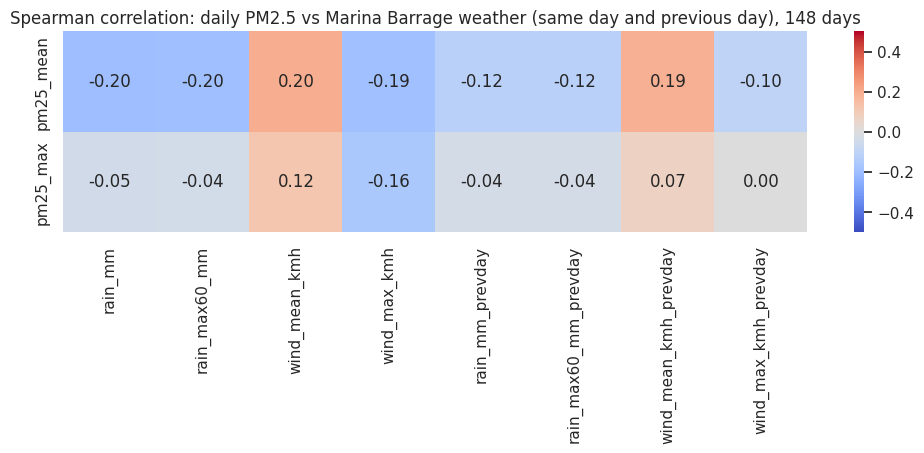

Daily mean PM2.5 by SAME-day rainfall:


,days,mean_pm25,median_pm25
rain_mm,,,
dry (0 mm),90,29.3,28.2
light (0-5),29,20.8,21.2
moderate (5-20),20,22.8,21.5
heavy (>20),9,24.0,19.8


Daily mean PM2.5 by PREVIOUS-day rainfall:


,days,mean_pm25,median_pm25
rain_mm_prevday,,,
dry (0 mm),89,28.1,26.3
light (0-5),31,23.3,25.3
moderate (5-20),18,23.5,19.8
heavy (>20),10,26.4,25.0


In [ ]:
day = pd.DataFrame({"pm25_mean": hourly["pm25"].resample("D").mean(), "pm25_max": hourly["pm25"].resample("D").max(),
                    "obs_hours": hourly["pm25"].resample("D").count()})
day = day[day["obs_hours"] >= 18].drop(columns="obs_hours")
J = day.join(daily).join(daily.shift(1).add_suffix("_prevday")).dropna()
wcols = list(daily.columns) + [c + "_prevday" for c in daily.columns]
cm = J.corr(method="spearman").loc[["pm25_mean", "pm25_max"], wcols]
plt.figure(figsize=(12, 2.6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-0.5, vmax=0.5)
plt.title(f"Spearman correlation: daily PM2.5 vs Marina Barrage weather (same day and previous day), {len(J)} days"); plt.show()

def rain_class(s): return pd.cut(s, [-0.1, 0.1, 5, 20, 1000], labels=["dry (0 mm)", "light (0-5)", "moderate (5-20)", "heavy (>20)"])
t1 = J.groupby(rain_class(J["rain_mm"]))["pm25_mean"].agg(days="count", mean_pm25="mean", median_pm25="median").round(1)
t2 = J.groupby(rain_class(J["rain_mm_prevday"]))["pm25_mean"].agg(days="count", mean_pm25="mean", median_pm25="median").round(1)
print("Daily mean PM2.5 by SAME-day rainfall:"); display(t1)
print("Daily mean PM2.5 by PREVIOUS-day rainfall:"); display(t2)

## Part 1 · 7. Save cleaned data

In [ ]:
hourly.to_csv("clean_hourly_marine_terrace.csv")
daily.to_csv("clean_daily_weather_marina_barrage.csv")
print("Saved clean_hourly_marine_terrace.csv", hourly.shape, "and clean_daily_weather_marina_barrage.csv", daily.shape)

Saved clean_hourly_marine_terrace.csv (4166, 5) and clean_daily_weather_marina_barrage.csv (273, 4)


In [ ]:
print("=== PART 1 SUMMARY ===")
print(f"Air quality: {len(pm_files)} files, {len(raw)} raw rows, {n_invalid} invalid/zero values set to NaN")
print(f"Hourly grid: {len(hourly)} hours ({hourly.index.min():%Y-%m-%d} to {hourly.index.max():%Y-%m-%d}); PM2.5 observed {int(hourly.pm25.notna().sum())} h, missing {int(hourly.pm25.isna().sum())} h")
print(f"PM2.5: mean {tot.mean():.1f}, max {tot.max():.1f} ug/m3; {(tot > 55).mean()*100:.1f}% of hours above 55; {int((tot > 150).sum())} hours above 150")
print(f"Weather: {len(daily)} days, columns kept: {list(daily.columns)}")
print(f"Autocorrelation lag-24h {acf[24]:.2f}, lag-48h {acf[48]:.2f}")

=== PART 1 SUMMARY ===
Air quality: 6 files, 18270 raw rows, 121 invalid/zero values set to NaN
Hourly grid: 4166 hours (2026-04-09 to 2026-09-30); PM2.5 observed 3693 h, missing 473 h
PM2.5: mean 26.2, max 431.1 ug/m3; 5.3% of hours above 55; 10 hours above 150
Weather: 273 days, columns kept: ['rain_mm', 'rain_max60_mm', 'wind_mean_kmh', 'wind_max_kmh']
Autocorrelation lag-24h 0.37, lag-48h 0.32


---
# Part 2: Feature Engineering (Phase 3)

**Input:** `hourly` (Marine Terrace, regular hourly grid) and `daily` (Marina Barrage weather) from Part 1.
**Output:** `features_all.csv` = leakage-safe features + forecast targets (+24h, +48h) + chronological split labels.

At every *forecast origin* `t` the model only uses information available at or before `t` and predicts PM2.5 at `t+24h` and `t+48h`.

| Group | Features (all known at time `t`) |
|---|---|
| Lag | PM2.5 at t, t-1, t-3, t-6, t-12, t-24, t-48 |
| Rolling | 6h / 24h mean and std, 24h max / min, **7-day mean** |
| Change | 1h / 6h / 24h difference, deviation from the 24h and 7-day means |
| Composition and sensor weather | PM1, PM1/PM2.5 fine fraction, particle count, temperature, humidity (current, lag, 24h mean) |
| Daily weather (Marina Barrage) | rainfall and wind of the **previous complete days**: last-day rain, 3-day and 7-day rain, heaviest 60-min rain, mean wind, 3-day mean wind, max wind, days since 1 mm of rain |
| Calendar | hour of day (sin / cos), day of week, weekend flag |

**Timing rule for daily weather.** A day's summary is only complete at midnight, so on date D the model may only use days up to D-1. The leakage test below checks this explicitly.

**Not used:** month / season indicators. The test period (late September) is a month that never appears in training, so a month feature cannot generalise. Spatial aggregation across stations is not possible with a single sensor.

## Part 2 · 1. Configuration

In [ ]:
HORIZONS = [24, 48]            # forecast horizons in hours
LAGS = [1, 3, 6, 12, 24, 48]   # lags of PM2.5 in hours
EVENT_THR = 55                 # NEA 1-hour "Elevated" edge: forecast above this = haze event
HIGH_THR = 150                 # NEA 1-hour "High" edge
TEST_FRAC, VAL_FRAC = 0.15, 0.15
PURGE = True                   # drop rows whose target window crosses a split boundary (prevents label leakage)
USE_DAY_OF_WEEK = True         # see the weekday check in section 7
assert (hourly.index.to_series().diff().dropna() == H).all()
print("Hourly rows:", len(hourly), "| daily weather days:", len(daily))

Hourly rows: 4166 | daily weather days: 273


## Part 2 · 2. Feature engineering
Every feature is a function of data up to time `t` only: `shift(k)` with k >= 0, trailing `rolling` windows, no centred windows and no future-looking fills.

In [ ]:
def weather_features(dly, idx):
    d = dly.copy(); d.index = pd.to_datetime(d.index)
    assert d.index.is_monotonic_increasing and (d.index.to_series().diff().dropna() == pd.Timedelta("1D")).all()
    f = pd.DataFrame(index=d.index)
    f["wx_rain_prev"] = d["rain_mm"]
    f["wx_rain_sum3"] = d["rain_mm"].rolling(3, min_periods=3).sum()
    f["wx_rain_sum7"] = d["rain_mm"].rolling(7, min_periods=7).sum()
    f["wx_rain60_prev"] = d["rain_max60_mm"]
    f["wx_wind_prev"] = d["wind_mean_kmh"]
    f["wx_wind_mean3"] = d["wind_mean_kmh"].rolling(3, min_periods=3).mean()
    f["wx_gust_prev"] = d["wind_max_kmh"]
    dsr, c = [], 14
    for wet in (d["rain_mm"] >= 1.0):
        c = 0 if wet else min(c + 1, 14)
        dsr.append(c)
    f["wx_days_since_rain"] = dsr
    f.index = f.index + pd.Timedelta(days=1)          # the summary of day D is known from 00:00 of day D+1
    return f.reindex(idx, method="ffill")

def build_features(hr, dly):
    """Feature matrix. Row t uses only hourly data <= t and daily weather of days before t's date."""
    y = hr["pm25"]
    X = pd.DataFrame(index=hr.index)
    X["pm25_now"] = y
    for k in LAGS:
        X[f"pm25_lag{k}"] = y.shift(k)
    for w in (6, 24):
        r = y.rolling(w, min_periods=w)
        X[f"pm25_rollmean{w}"] = r.mean()
        X[f"pm25_rollstd{w}"] = r.std()
    X["pm25_rollmean168"] = y.rolling(168, min_periods=126).mean()     # 7-day baseline (needs 75% of hours)
    X["pm25_rollmax24"] = y.rolling(24, min_periods=24).max()
    X["pm25_rollmin24"] = y.rolling(24, min_periods=24).min()
    X["pm25_diff1"] = y.diff(1)
    X["pm25_diff6"] = y.diff(6)
    X["pm25_diff24"] = y.diff(24)
    X["pm25_vs_roll24"] = y - X["pm25_rollmean24"]
    X["pm25_vs_roll168"] = y - X["pm25_rollmean168"]
    X["pm1_now"] = hr["pm1"]
    X["fine_fraction"] = hr["pm1"] / y
    X["um003_now"] = hr["um003"]
    X["um003_lag24"] = hr["um003"].shift(24)
    X["temp_now"] = hr["temp"]
    X["temp_rollmean24"] = hr["temp"].rolling(24, min_periods=24).mean()
    X["rh_now"] = hr["rh"]
    X["rh_rollmean24"] = hr["rh"].rolling(24, min_periods=24).mean()
    X["rh_diff6"] = hr["rh"].diff(6)
    X = X.join(weather_features(dly, hr.index))
    hh = hr.index.hour
    X["hour_sin"] = np.sin(2 * np.pi * hh / 24)
    X["hour_cos"] = np.cos(2 * np.pi * hh / 24)
    X["dow"] = hr.index.dayofweek
    X["is_weekend"] = (hr.index.dayofweek >= 5).astype(int)
    return X

F = build_features(hourly, daily)
if not USE_DAY_OF_WEEK:
    F = F.rename(columns={"dow": "aux_dow", "is_weekend": "aux_is_weekend"})
FEATURES = [c for c in F.columns if not c.startswith("aux_")]
print("Feature matrix:", F.shape, "| model inputs:", len(FEATURES))

Feature matrix: (4166, 40) | model inputs: 40


## Part 2 · 3. Targets, event labels and the modelling table
- `target_h24` / `target_h48`: PM2.5 at `t+24h` / `t+48h`.
- `event_h*`: 1 if that future value exceeds 55 ug/m3 (NEA "Elevated"), the haze-event label for alerts. `high_h*`: above 150 (NEA "High").
- Rows are dropped when any feature is missing (start of the series, the first hours after each data gap). Rows without a target are excluded for that horizon.

In [ ]:
T = pd.DataFrame(index=hourly.index)
for h in HORIZONS:
    tgt = hourly["pm25"].shift(-h)
    T[f"target_h{h}"] = tgt
    T[f"event_h{h}"] = (tgt > EVENT_THR).astype(float).where(tgt.notna())
    T[f"high_h{h}"] = (tgt > HIGH_THR).astype(float).where(tgt.notna())

data = F.join(T)
n0 = len(data)
data = data.dropna(subset=list(F.columns))
print(f"Rows: {n0} -> {len(data)} (dropped {n0 - len(data)} rows with missing features)")
print("Rows with a valid target: " + ", ".join(f"h{h}: {int(data[f'target_h{h}'].notna().sum())}" for h in HORIZONS))
print("Missing feature values left:", int(data[FEATURES].isna().sum().sum()))
data[["pm25_now", "pm25_lag24", "pm25_rollmean24", "wx_rain_prev", "wx_wind_mean3", "target_h24", "target_h48"]].tail(3)

Rows: 4166 -> 3275 (dropped 891 rows with missing features)
Rows with a valid target: h24: 3155, h48: 3107
Missing feature values left: 0


,pm25_now,pm25_lag24,pm25_rollmean24,wx_rain_prev,wx_wind_mean3,target_h24,target_h48
datetime,,,,,,,
2026-09-30 06:00:00,49.6,22.4,45.266667,0.0,5.133333,NaN,NaN
2026-09-30 07:00:00,49.3,19.5,46.508333,0.0,5.133333,NaN,NaN
2026-09-30 08:00:00,50.1,30.8,47.312500,0.0,5.133333,NaN,NaN


## Part 2 · 4. Leakage tests
1. **Features use only the past.** For random forecast origins `t`, rebuild the features from the hourly data up to `t` and only the **completed days before `t`'s date**. The row for `t` must equal the one built from the full data. If any feature used the future (including the weather of `t`'s own day) the rows would differ.
2. **Targets are aligned.** `target_hH` at `t` equals the PM2.5 observed H hours later.

In [ ]:
def leakage_check(n_checks=40, seed=0):
    rng = np.random.default_rng(seed)
    full = build_features(hourly, daily)
    cand = full.dropna().index
    picks = rng.choice(len(cand), size=min(n_checks, len(cand)), replace=False)
    bad = []
    for i in picks:
        t = pd.Timestamp(cand[i])
        known_days = daily.loc[: t.normalize() - pd.Timedelta(days=1)]       # only completed days are known at t
        trunc = build_features(hourly.loc[:t], known_days)
        if not np.allclose(trunc.loc[t].values.astype(float), full.loc[t].values.astype(float), equal_nan=True):
            bad.append(t)
    return bad

leaks = leakage_check()
assert not leaks, f"Future information leaks into features at: {leaks[:5]}"
print("Test 1 passed: features at t are identical when everything after t (and t's own day of weather) is removed (40 random origins).")

for h in HORIZONS:
    d = data[data[f"target_h{h}"].notna()]
    sample = d.index[::53]
    assert np.allclose(d.loc[sample, f"target_h{h}"].values, hourly["pm25"].reindex(sample + h * H).values)
print("Test 2 passed: targets equal PM2.5 observed H hours later.")

Test 1 passed: features at t are identical when everything after t (and t's own day of weather) is removed (40 random origins).
Test 2 passed: targets equal PM2.5 observed H hours later.


## Part 2 · 5. Chronological train / validation / test split (no shuffling)
Test = last 15% of usable rows, validation = the 15% before it, training = everything earlier.

**Purging:** the target of a row at `t` is the value at `t+h`. Rows whose target lies in the next period are dropped (`PURGE=True`), so no label crosses a boundary.

In [ ]:
def make_split(idx, h, test_frac=TEST_FRAC, val_frac=VAL_FRAC, purge=PURGE):
    n = len(idx)
    test_start = idx[n - int(round(test_frac * n))]
    val_start = idx[n - int(round((test_frac + val_frac) * n))]
    s = pd.Series("train", index=idx)
    s[idx >= val_start] = "val"
    s[idx >= test_start] = "test"
    if purge:
        td = h * H
        s[(s == "train").values & (idx + td >= val_start)] = "purged"
        s[(s == "val").values & (idx + td >= test_start)] = "purged"
    return s

for h in HORIZONS:
    rows = data.index[data[f"target_h{h}"].notna()]
    sp = make_split(rows, h)
    data[f"split_h{h}"] = sp.reindex(data.index).fillna("no_target")
    tr, va, te = (sp.index[sp == k] for k in ("train", "val", "test"))
    assert tr.max() < va.min() and va.max() < te.min()
    if PURGE:
        assert tr.max() + h * H < va.min() and va.max() + h * H < te.min()

rows_out = []
for h in HORIZONS:
    for k in ["train", "val", "test", "purged"]:
        d = data[data[f"split_h{h}"] == k]
        rows_out.append({"horizon": f"+{h}h", "split": k, "rows": len(d), "from": d.index.min(), "to": d.index.max(),
                         "target_mean": d[f"target_h{h}"].mean(), "target_max": d[f"target_h{h}"].max(),
                         "hours>55": int(d[f"event_h{h}"].sum()), "hours>150": int(d[f"high_h{h}"].sum())})
split_table = pd.DataFrame(rows_out).round(1)
display(split_table)
for h in HORIZONS:
    m = split_table[split_table.horizon == f"+{h}h"].set_index("split")["target_mean"]
    print(f"+{h}h mean target: train {m['train']} | val {m['val']} | test {m['test']}  (large gaps = regime shift)")

,horizon,split,rows,from,to,target_mean,target_max,hours>55,hours>150
0,+24h,train,2185,2026-04-15 00:00:00,2026-08-16 16:00:00,20.1,224.1,24,3
1,+24h,val,449,2026-08-17 17:00:00,2026-09-08 15:00:00,37.9,130.6,48,0
2,+24h,test,473,2026-09-09 16:00:00,2026-09-29 08:00:00,48.7,431.1,102,6
3,+24h,purged,48,2026-08-16 17:00:00,2026-09-09 15:00:00,43.4,106.6,9,0
4,+48h,train,2127,2026-04-15 00:00:00,2026-08-15 06:00:00,20.1,224.1,24,3
5,+48h,val,418,2026-08-17 07:00:00,2026-09-06 22:00:00,36.0,93.3,32,0
6,+48h,test,466,2026-09-08 23:00:00,2026-09-28 08:00:00,48.7,431.1,102,6
7,+48h,purged,96,2026-08-15 07:00:00,2026-09-08 22:00:00,43.1,130.6,12,0


+24h mean target: train 20.1 | val 37.9 | test 48.7  (large gaps = regime shift)
+48h mean target: train 20.1 | val 36.0 | test 48.7  (large gaps = regime shift)


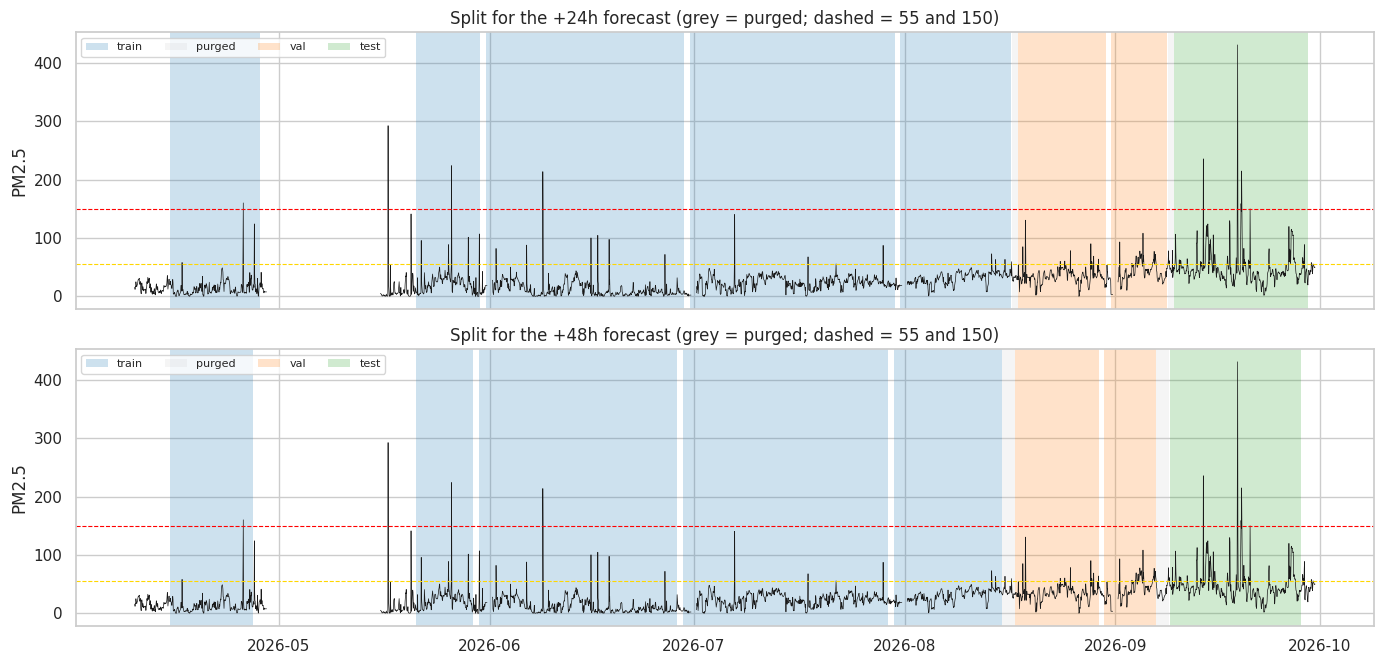

In [ ]:
def runs(s):
    grp = (s != s.shift()).cumsum()
    for _, g in s.groupby(grp):
        yield g.iloc[0], g.index[0], g.index[-1]

colors = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green", "purged": "lightgrey"}
fig, axes = plt.subplots(len(HORIZONS), 1, figsize=(14, 3.4 * len(HORIZONS)), sharex=True)
for ax, h in zip(np.atleast_1d(axes), HORIZONS):
    ax.plot(hourly.index, hourly["pm25"], color="k", lw=0.5)
    for lab, a, b in runs(data[f"split_h{h}"]):
        if lab in colors:
            ax.axvspan(a, b, color=colors[lab], alpha=0.22, lw=0, label=lab)
    ax.axhline(EVENT_THR, color="gold", ls="--", lw=0.8); ax.axhline(HIGH_THR, color="red", ls="--", lw=0.8)
    h_, l_ = ax.get_legend_handles_labels(); uniq = dict(zip(l_, h_))
    ax.legend(uniq.values(), uniq.keys(), ncol=4, fontsize=8, loc="upper left")
    ax.set_title(f"Split for the +{h}h forecast (grey = purged; dashed = 55 and 150)"); ax.set_ylabel("PM2.5")
plt.tight_layout(); plt.show()

## Part 2 · 6. Feature groups and dictionary
What each input means in plain words, and why it can help forecast PM2.5 a day or two ahead.

In [ ]:
import re
def group_of(c):
    if c.startswith(("hour_", "dow", "is_weekend")): return "calendar"
    if c.startswith("wx_"): return "daily weather"
    if c.startswith(("pm1", "fine", "um003", "temp", "rh")): return "composition & sensor weather"
    if c in ("pm25_now", "pm25_diff1", "pm25_diff6", "pm25_diff24", "pm25_vs_roll24", "pm25_vs_roll168"): return "level & change"
    if "_lag" in c: return "lag"
    return "rolling"

groups = pd.Series({c: group_of(c) for c in FEATURES})
STATIC = {
    "pm25_now": ("PM2.5 at the forecast origin", "Haze persists for hours to days, so the current level is the starting point"),
    "pm25_rollmean168": ("Average PM2.5 over the last 7 days", "Slow baseline: separates a clean week from a hazy one"),
    "pm25_rollmax24": ("Highest PM2.5 in the last 24 h", "Recent peak: did a spike just happen"),
    "pm25_rollmin24": ("Lowest PM2.5 in the last 24 h", "Recent floor: how clean the air got"),
    "pm25_diff1": ("Change over the last 1 h", "Momentum: building or clearing right now"),
    "pm25_diff6": ("Change over the last 6 h", "Medium-term trend"),
    "pm25_diff24": ("Change over the last 24 h", "Day-on-day trend"),
    "pm25_vs_roll24": ("Current PM2.5 minus its 24 h average", "How far above or below the recent baseline"),
    "pm25_vs_roll168": ("Current PM2.5 minus its 7-day average", "How unusual the current level is for this week"),
    "pm1_now": ("PM1 (finest particles)", "Combustion smoke is dominated by very fine particles"),
    "fine_fraction": ("PM1 / PM2.5 ratio", "Share of very fine particles: separates smoke-like from coarse / dust-like air"),
    "um003_now": ("Particle count (0.3 um and larger) per cm3", "Counts particles instead of weighing them, so it reacts early to a new plume"),
    "um003_lag24": ("Particle count 24 h earlier", "Same hour yesterday"),
    "temp_now": ("Sensor temperature now", "Weather context (heat, sun, rain)"),
    "temp_rollmean24": ("Average temperature, last 24 h", "Smoothed weather context"),
    "rh_now": ("Relative humidity now", "Humid air and rain wash out or swell particles; also a known optical-sensor bias"),
    "rh_rollmean24": ("Average humidity, last 24 h", "Smoothed weather context"),
    "rh_diff6": ("Change in humidity over 6 h", "Showers and fronts appear as humidity jumps"),
    "wx_rain_prev": ("Rainfall total of the last complete day (mm)", "Rain washes particles out of the air"),
    "wx_rain_sum3": ("Rainfall over the last 3 complete days (mm)", "Recent wet spell"),
    "wx_rain_sum7": ("Rainfall over the last 7 complete days (mm)", "Wet or dry week"),
    "wx_rain60_prev": ("Heaviest 60-min rainfall of the last complete day (mm)", "Shower intensity"),
    "wx_wind_prev": ("Mean wind speed of the last complete day (km/h)", "Stronger wind disperses haze; calm days let it build up"),
    "wx_wind_mean3": ("Mean wind speed over the last 3 complete days (km/h)", "Smoothed ventilation"),
    "wx_gust_prev": ("Max wind speed of the last complete day (km/h)", "Gusts and squall lines"),
    "wx_days_since_rain": ("Days since a day with at least 1 mm of rain (max 14)", "Long dry spells let particles accumulate"),
    "hour_sin": ("Hour of day, sine part", "Daily cycle; the sine / cosine pair avoids a jump at midnight"),
    "hour_cos": ("Hour of day, cosine part", "Pairs with hour_sin"),
    "dow": ("Day of week (0 = Monday)", "Weekly activity cycle (traffic, industry)"),
    "is_weekend": ("Saturday or Sunday", "Weekend activity pattern"),
}
def describe(c):
    if c in STATIC: return STATIC[c]
    m = re.fullmatch(r"pm25_lag(\d+)", c)
    if m:
        k = int(m.group(1))
        return (f"PM2.5 {k} h before the origin",
                "Same hour yesterday / the day before: daily pattern and multi-day persistence" if k in (24, 48) else "Recent history: short-term persistence and trend")
    m = re.fullmatch(r"pm25_rollmean(\d+)", c)
    if m: return (f"Average PM2.5 over the last {m.group(1)} h", "Smooths sensor noise; recent baseline")
    m = re.fullmatch(r"pm25_rollstd(\d+)", c)
    if m: return (f"Standard deviation of PM2.5 over the last {m.group(1)} h", "Volatility: unsettled air often accompanies spikes")
    raise KeyError(f"no description for {c}")

fd = pd.DataFrame({c: (groups[c], *describe(c)) for c in FEATURES}, index=["group", "what it is", "why it may help"]).T.sort_values("group", kind="stable")
assert len(fd) == len(FEATURES)
display(groups.value_counts().rename("n_features").to_frame())
with pd.option_context("display.max_rows", 80, "display.max_colwidth", 90, "display.width", 250):
    display(fd)

,n_features
composition & sensor weather,9
daily weather,8
rolling,7
level & change,6
lag,6
calendar,4


,group,what it is,why it may help
hour_sin,calendar,"Hour of day, sine part",Daily cycle; the sine / cosine pair avoids a jump at midnight
hour_cos,calendar,"Hour of day, cosine part",Pairs with hour_sin
dow,calendar,Day of week (0 = Monday),"Weekly activity cycle (traffic, industry)"
is_weekend,calendar,Saturday or Sunday,Weekend activity pattern
pm1_now,composition & sensor weather,PM1 (finest particles),Combustion smoke is dominated by very fine particles
fine_fraction,composition & sensor weather,PM1 / PM2.5 ratio,Share of very fine particles: separates smoke-like from coarse / dust-like air
um003_now,composition & sensor weather,Particle count (0.3 um and larger) per cm3,"Counts particles instead of weighing them, so it reacts early to a new plume"
um003_lag24,composition & sensor weather,Particle count 24 h earlier,Same hour yesterday
temp_now,composition & sensor weather,Sensor temperature now,"Weather context (heat, sun, rain)"
temp_rollmean24,composition & sensor weather,"Average temperature, last 24 h",Smoothed weather context


## Part 2 · 7. Train-only relationships
Everything here uses the **training rows only**, so nothing about validation or test influences feature decisions.

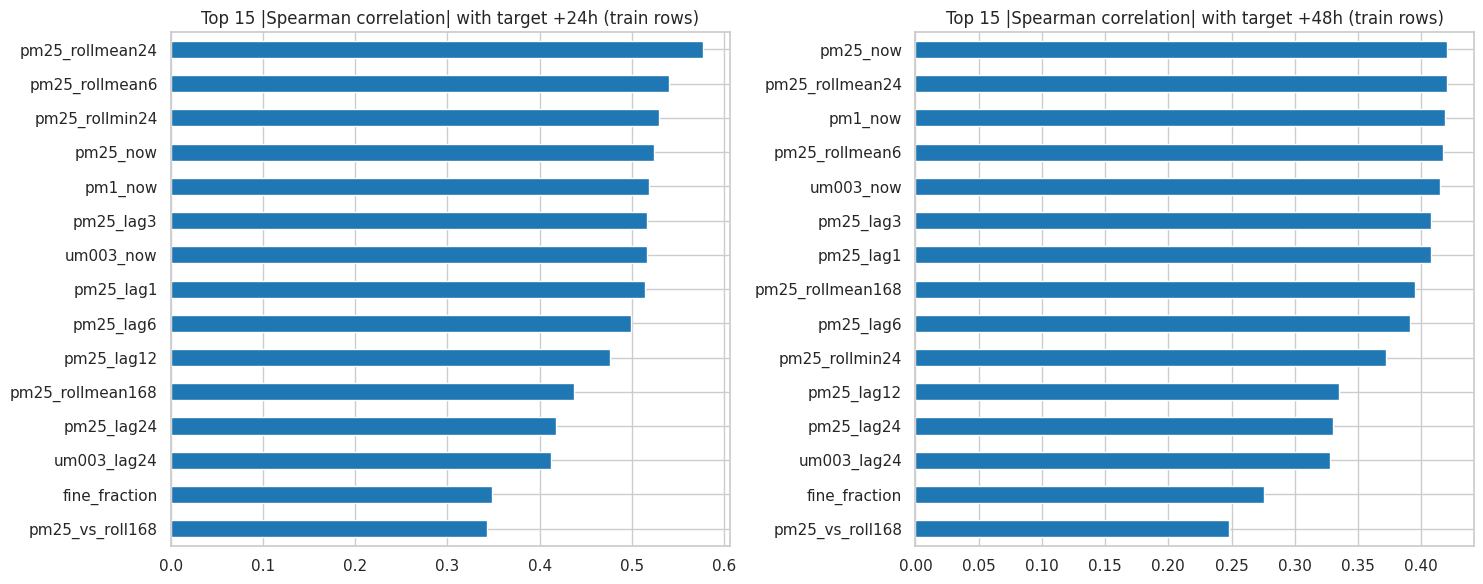

Daily-weather features vs +24h target (train, Spearman):


,spearman_with_target_h24
wx_rain_sum7,-0.219
wx_rain_sum3,-0.084
wx_gust_prev,-0.021
wx_rain60_prev,-0.007
wx_rain_prev,-0.004
wx_days_since_rain,0.002
wx_wind_prev,0.227
wx_wind_mean3,0.236


In [ ]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(15, 6))
for ax, h in zip(axes, HORIZONS):
    tr = data[data[f"split_h{h}"] == "train"]
    corr = tr[FEATURES].corrwith(tr[f"target_h{h}"], method="spearman").sort_values(key=abs, ascending=False).head(15)[::-1]
    corr.plot.barh(ax=ax, color=["tab:red" if v < 0 else "tab:blue" for v in corr])
    ax.set_title(f"Top 15 |Spearman correlation| with target +{h}h (train rows)")
plt.tight_layout(); plt.show()

wx_feats = [c for c in FEATURES if c.startswith("wx_")]
tr24 = data[data["split_h24"] == "train"]
print("Daily-weather features vs +24h target (train, Spearman):")
display(tr24[wx_feats].corrwith(tr24["target_h24"], method="spearman").round(3).to_frame("spearman_with_target_h24").sort_values("spearman_with_target_h24"))

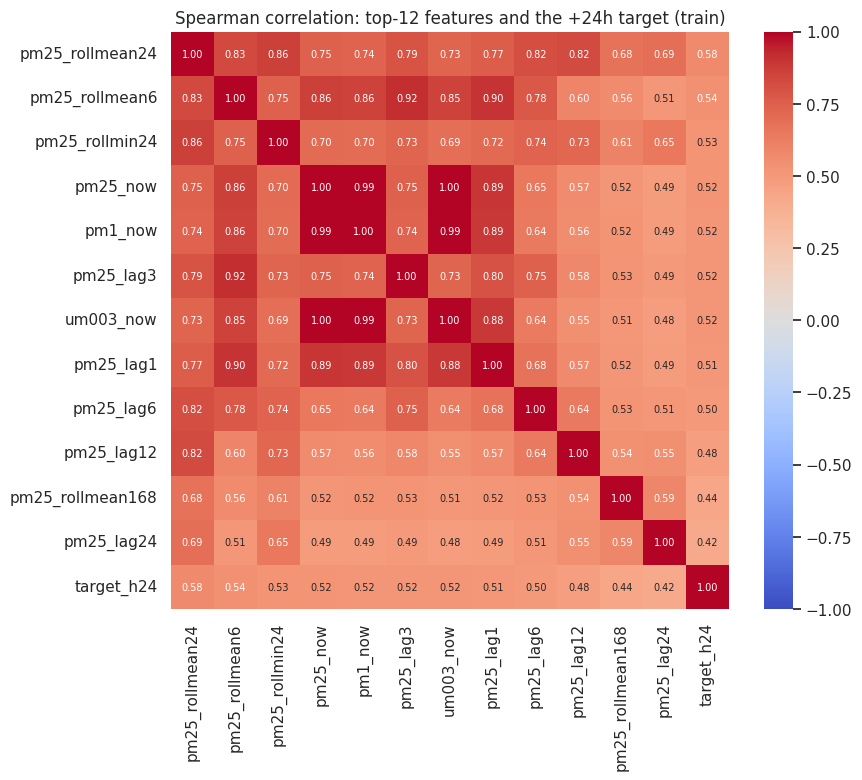

In [ ]:
# Heatmap: the 12 strongest features + the target (train rows, +24h). Shows which features carry the same information.
top = tr24[FEATURES].corrwith(tr24["target_h24"], method="spearman").abs().sort_values(ascending=False).head(12).index.tolist()
plt.figure(figsize=(9, 7.5))
sns.heatmap(tr24[top + ["target_h24"]].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Spearman correlation: top-12 features and the +24h target (train)"); plt.show()

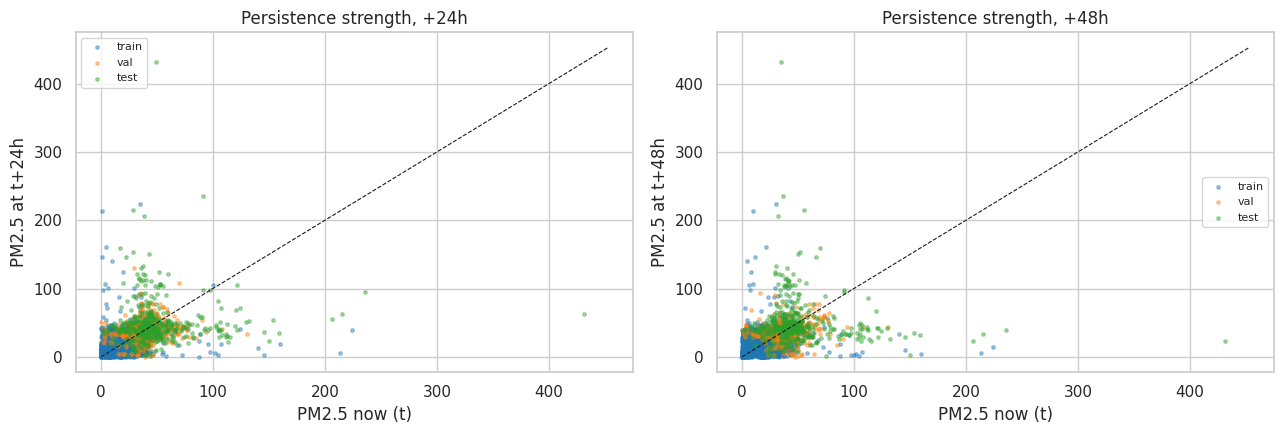

In [ ]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(13, 4.5))
for ax, h in zip(axes, HORIZONS):
    for k in ["train", "val", "test"]:
        d = data[data[f"split_h{h}"] == k]
        ax.scatter(d["pm25_now"], d[f"target_h{h}"], s=6, alpha=0.4, color=colors[k], label=k)
    lim = [0, data["pm25_now"].max() * 1.05]
    ax.plot(lim, lim, "k--", lw=0.8); ax.set_xlabel("PM2.5 now (t)"); ax.set_ylabel(f"PM2.5 at t+{h}h")
    ax.set_title(f"Persistence strength, +{h}h"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Weekday check on training rows: is there a weekly pattern, and how many distinct dates back it?
trw = data[data["split_h24"] == "train"]
chk = trw.groupby("dow")["target_h24"].agg(mean_target="mean", median_target="median", hours="count").round(1)
chk["distinct_dates"] = trw.groupby("dow").apply(lambda d: d.index.normalize().nunique())
chk.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][:len(chk)] if len(chk) == 7 else chk.index
display(chk)

,mean_target,median_target,hours,distinct_dates
Mon,19.8,19.1,294,13
Tue,19.0,18.8,281,14
Wed,21.2,20.0,303,13
Thu,18.6,17.2,330,15
Fri,19.8,17.8,333,15
Sat,19.8,19.4,327,14
Sun,22.3,20.8,317,15


## Part 2 · 8. Sanity baselines (preview of Phase 4)
Simple reference forecasts show what any model must beat. For +24h and +48h the "seasonal naive" forecast (same hour one or two days before the target) is identical to persistence of the current value. Formal evaluation is in Part 3.

In [ ]:
rows_out = []
for h in HORIZONS:
    tr = data[data[f"split_h{h}"] == "train"]
    train_mean = tr[f"target_h{h}"].mean()
    for sp in ["val", "test"]:
        d = data[data[f"split_h{h}"] == sp]; yv = d[f"target_h{h}"]
        for name, p in {"persistence (value now)": d["pm25_now"], "24h trailing mean": d["pm25_rollmean24"],
                        "7-day trailing mean": d["pm25_rollmean168"], "train mean": pd.Series(train_mean, index=d.index)}.items():
            rows_out.append({"horizon": f"+{h}h", "split": sp, "baseline": name, "RMSE": np.sqrt(((yv - p) ** 2).mean()), "MAE": (yv - p).abs().mean()})
display(pd.DataFrame(rows_out).pivot_table(index=["horizon", "baseline"], columns="split", values=["RMSE", "MAE"]).round(1))

MAE        RMSE      
split                            test   val  test   val
horizon baseline                                       
+24h    24h trailing mean        22.8  13.2  36.4  17.3
        7-day trailing mean      19.7  11.4  33.8  15.9
        persistence (value now)  27.3  15.1  45.4  19.9
        train mean               29.6  19.5  43.5  23.6
+48h    24h trailing mean        26.0  12.6  40.1  16.5
        7-day trailing mean      20.4  10.8  34.4  14.4
        persistence (value now)  28.2  14.8  48.3  19.9
        train mean               29.5  17.8  43.6  21.2

## Part 2 · 9. Save the modelling table

In [ ]:
out = data.copy(); out.index.name = "datetime"
out.to_csv("features_all.csv")
print("Saved features_all.csv", out.shape, "| feature columns:", len(FEATURES))

print("=== PART 2 SUMMARY ===")
print(f"Features: {len(FEATURES)} in {groups.nunique()} groups | modelling rows: {len(data)} (dropped {n0 - len(data)} with missing features)")
for h in HORIZONS:
    c = data[f"split_h{h}"].value_counts()
    print(f"+{h}h  train {c.get('train',0)} | val {c.get('val',0)} | test {c.get('test',0)} | purged {c.get('purged',0)} | no target {c.get('no_target',0)}"
          f" | hours>55 in test: {int(data.loc[data[f'split_h{h}']=='test', f'event_h{h}'].sum())}, >150: {int(data.loc[data[f'split_h{h}']=='test', f'high_h{h}'].sum())}")
print("Leakage tests: passed")

Saved features_all.csv (3275, 48) | feature columns: 40
=== PART 2 SUMMARY ===
Features: 40 in 6 groups | modelling rows: 3275 (dropped 891 with missing features)
+24h  train 2185 | val 449 | test 473 | purged 48 | no target 120 | hours>55 in test: 102, >150: 6
+48h  train 2127 | val 418 | test 466 | purged 96 | no target 168 | hours>55 in test: 102, >150: 6
Leakage tests: passed


---
# Part 3: Baselines and Candidate Models (Phase 4)

**Evaluation protocol (same for every model)**
- For each horizon `h` (+24h, +48h) and each forecast origin `t` in the validation or test period, a model may use data **up to `t` only** (plus completed days of weather) and must predict PM2.5 at `t+h`.
- Every model is trained / fitted on the **training rows only**. Validation is used to compare models; the **test set is only reported, never used to choose anything**.
- Metrics: RMSE and MAE (primary), MAPE (valid because PM2.5 is never zero after cleaning), and *skill vs naive* = 1 - RMSE / RMSE(naive).

**Models**

| Type | Model | Notes |
|---|---|---|
| Baseline | Naive: y(t+h) = y(t) | For h = 24 and 48 the *seasonal naive* forecast is exactly this value |
| Baseline | 24h and 7-day moving averages | Stronger references than naive when the series is noisy |
| Classical | SARIMAX(1,1,1) + daily cycle | Hour-of-day sine / cosine as exogenous inputs; parameters fitted on train, then applied to the last 14 days of data before each origin (no refit) |
| Exp. smoothing | Holt-Winters | Damped additive trend, additive daily seasonality (24 h), parameters fitted on train |
| ML | LightGBM, variants a / b / c | (a) level and (b) change from now, both with all features; (c) **scale-free**: ratio-type features and the log of the ratio y(t+h) / y(t) |
| ML | Ridge, scale-free | Same inputs and target as (c), a low-variance linear model |
| Ablation | (c) and Ridge with / without daily weather | Isolates what rain and wind add |

In [ ]:
!pip -q install lightgbm statsmodels scikit-learn
import time
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import lightgbm as lgb
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def split_idx(h, sp):  return data.index[data[f"split_h{h}"] == sp]
def eval_idx(h):       return data.index[data[f"split_h{h}"].isin(["val", "test"])]
def actual(h, idx):    return data.loc[idx, f"target_h{h}"]

preds = {h: {} for h in HORIZONS}     # preds[h][model] = Series indexed by forecast origin (val + test)
fitted = {}                           # fitted ML models, kept for interpretation later
print("Horizons:", HORIZONS, "| features for the all-feature ML models:", len(FEATURES))

Horizons: [24, 48] | features for the all-feature ML models: 40


## Part 3 · 1. Baselines

In [ ]:
for h in HORIZONS:
    ix = eval_idx(h)
    preds[h]["Naive (y_t)"] = data.loc[ix, "pm25_now"]
    preds[h]["24h moving average"] = data.loc[ix, "pm25_rollmean24"]
    preds[h]["7-day moving average"] = data.loc[ix, "pm25_rollmean168"]
print({h: list(v) for h, v in preds.items()})

{24: ['Naive (y_t)', '24h moving average', '7-day moving average'], 48: ['Naive (y_t)', '24h moving average', '7-day moving average']}


## Part 3 · 2. Input series for the classical models
SARIMAX and Holt-Winters need an unbroken series. Gaps of up to 30 h are bridged by time interpolation **for these two models' input windows only**. This uses data on both sides of a gap, but every such gap lies before the origin being forecast, so nothing after the origin is used. The 17-day outage is not bridged: the models are fitted only on the data after it.

In [ ]:
y = hourly["pm25"].asfreq("h")
y_cls = y.interpolate(method="time", limit=30, limit_area="inside")

val_min = min(split_idx(h, "val").min() for h in HORIZONS)
nan_before = y_cls[y_cls.isna() & (y_cls.index < val_min)].index
start_cls = (nan_before.max() + H) if len(nan_before) else y_cls.index[0]
print("Classical models are fitted on data from", start_cls, "onwards (after the last gap longer than 30 h)")
WINDOW = 14 * 24

Classical models are fitted on data from 2026-05-15 22:00:00 onwards (after the last gap longer than 30 h)


## Part 3 · 3. SARIMAX (classical)
Fitted once on the training period. For each forecast origin the *same parameters* are applied to the preceding 14 days, and a forecast `h` steps ahead is produced. The model is never re-estimated on validation or test information.

In [ ]:
def hour_exog(idx):
    hr = np.asarray(idx.hour)
    return pd.DataFrame({"hr_sin": np.sin(2 * np.pi * hr / 24), "hr_cos": np.cos(2 * np.pi * hr / 24)}, index=idx)

def window_at(t):
    w = y_cls.loc[t - WINDOW * H: t]
    return w.ffill().bfill() if w.isna().any() else w

SARIMAX_ORDER = (1, 1, 1)
t0 = time.time()
for h in HORIZONS:
    fit_end = split_idx(h, "train").max() + h * H
    y_fit = y_cls.loc[start_cls:fit_end]
    base = SARIMAX(y_fit, exog=hour_exog(y_fit.index), order=SARIMAX_ORDER).fit(disp=False)
    out = {}
    for t in eval_idx(h):
        w = window_at(t)
        r = base.apply(w, exog=hour_exog(w.index), refit=False)
        fut = pd.date_range(t + H, periods=h, freq="h")
        out[t] = float(r.forecast(steps=h, exog=hour_exog(fut)).iloc[-1])
    preds[h]["SARIMAX(1,1,1)+daily cycle"] = pd.Series(out).clip(lower=0)
    print(f"+{h}h SARIMAX done: AIC on train {base.aic:.0f}, params {dict(base.params.round(3))}")
print(f"{time.time() - t0:.0f}s")

+24h SARIMAX done: AIC on train 17922, params {'hr_sin': np.float64(-0.672), 'hr_cos': np.float64(0.915), 'ar.L1': np.float64(0.393), 'ma.L1': np.float64(-0.949), 'sigma2': np.float64(167.761)}
+48h SARIMAX done: AIC on train 17852, params {'hr_sin': np.float64(-0.688), 'hr_cos': np.float64(0.909), 'ar.L1': np.float64(0.393), 'ma.L1': np.float64(-0.95), 'sigma2': np.float64(168.459)}
47s


## Part 3 · 4. Holt-Winters exponential smoothing
Damped additive trend with additive daily seasonality (24 h). The smoothing parameters are fitted on the training period; for each origin the filter runs over the preceding 14 days with those parameters fixed.

In [ ]:
HW_KW = dict(trend="add", damped_trend=True, seasonal="add", seasonal_periods=24)
def hw_param(res, *names):
    for n in names:
        if n in res.params and res.params[n] is not None:
            return float(res.params[n])
    raise KeyError(names)

t0 = time.time()
for h in HORIZONS:
    fit_end = split_idx(h, "train").max() + h * H
    y_fit = y_cls.loc[start_cls:fit_end]
    assert y_fit.notna().all()
    hw0 = ExponentialSmoothing(y_fit, initialization_method="estimated", **HW_KW).fit()
    prm = dict(smoothing_level=hw_param(hw0, "smoothing_level"),
               smoothing_trend=hw_param(hw0, "smoothing_trend", "smoothing_slope"),
               smoothing_seasonal=hw_param(hw0, "smoothing_seasonal"),
               damping_trend=hw_param(hw0, "damping_trend", "damping_slope"))
    out = {}
    for t in eval_idx(h):
        m = ExponentialSmoothing(window_at(t), initialization_method="heuristic", **HW_KW).fit(optimized=False, **prm)
        out[t] = float(m.forecast(h).iloc[-1])
    preds[h]["Holt-Winters (damped, s=24)"] = pd.Series(out).clip(lower=0)
    print(f"+{h}h Holt-Winters done: " + ", ".join(f"{k}={v:.3f}" for k, v in prm.items()))
print(f"{time.time() - t0:.0f}s")

+24h Holt-Winters done: smoothing_level=0.295, smoothing_trend=0.000, smoothing_seasonal=0.000, damping_trend=0.955
+48h Holt-Winters done: smoothing_level=0.295, smoothing_trend=0.000, smoothing_seasonal=0.000, damping_trend=0.955
31s


## Part 3 · 5. Machine learning: LightGBM and Ridge
Default (untuned) settings; tuning is Phase 5. Ridge standardises features with **training rows only** (inside the pipeline).

**Why several variants?** The training period (April to August) is much calmer than validation and test, so models built on absolute levels have to extrapolate. Variants (a) and (b) use all absolute-level features and show what happens. Variant (c) uses **scale-free** inputs (ratios to the 24 h and 7-day means, PM1/PM2.5, hour of day) and predicts the **log of the ratio** y(t+h) / y(t), which behaves the same at 20 or 80 ug/m3. A second version adds three daily-weather inputs (log of 3-day rain, 3-day mean wind, days since rain) so that the effect of weather can be read off directly. Design (c) was inspired by a failure seen on validation data in an earlier iteration of this project, so its validation scores may be slightly optimistic; the test set played no role.

In [ ]:
LGB_PARAMS = dict(n_estimators=200, learning_rate=0.03, num_leaves=7, min_child_samples=20,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0,
                  random_state=42, verbose=-1)
make_lgb = lambda: lgb.LGBMRegressor(**LGB_PARAMS)
make_ridge = lambda: make_pipeline(StandardScaler(), Ridge(alpha=100.0))

XA = data[FEATURES]
ma24, ma168 = data["pm25_rollmean24"], data["pm25_rollmean168"]
XR = pd.DataFrame({
    "rel_now_ma24":   data["pm25_now"] / ma24,
    "rel_ma6_ma24":   data["pm25_rollmean6"] / ma24,
    "rel_lag24_ma24": data["pm25_lag24"] / ma24,
    "rel_lag48_ma24": data["pm25_lag48"] / ma24,
    "rel_max24_ma24": data["pm25_rollmax24"] / ma24,
    "rel_diff6_ma24": data["pm25_diff6"] / ma24,
    "cv24":           data["pm25_rollstd24"] / ma24,
    "rel_now_ma168":  data["pm25_now"] / ma168,
    "fine_fraction":  data["fine_fraction"],
    "hour_sin":       data["hour_sin"],
    "hour_cos":       data["hour_cos"],
})
XRW = XR.assign(wx_log_rain3=np.log1p(data["wx_rain_sum3"]), wx_wind_mean3=data["wx_wind_mean3"], wx_days_since_rain=data["wx_days_since_rain"])
for X_ in (XR, XRW):
    assert X_.notna().all().all() and np.isfinite(X_.values).all()

def fit_ml(h, make, mode, X):
    tr = data[data[f"split_h{h}"] == "train"]
    ix = eval_idx(h)
    ytr, now_tr, now_ev = tr[f"target_h{h}"], tr["pm25_now"], data.loc[ix, "pm25_now"]
    z = {"level": ytr, "change": ytr - now_tr, "logratio": np.log(ytr / now_tr)}[mode]
    m = make().fit(X.loc[tr.index], z)
    raw = pd.Series(m.predict(X.loc[ix]), index=ix)
    if mode == "logratio":
        raw = raw.clip(-1.5, 1.5)                  # safety bound: ratio between about 0.22 and 4.5
    p = {"level": raw, "change": raw + now_ev, "logratio": now_ev * np.exp(raw)}[mode]
    return p.clip(lower=0), m

ML_MODELS = {"LightGBM (a: level, all features)":      (make_lgb,   "level",    XA),
             "LightGBM (b: change, all features)":     (make_lgb,   "change",   XA),
             "LightGBM (c: scale-free)":               (make_lgb,   "logratio", XR),
             "LightGBM (c + daily weather)":           (make_lgb,   "logratio", XRW),
             "Ridge (scale-free)":                     (make_ridge, "logratio", XR),
             "Ridge (scale-free + daily weather)":     (make_ridge, "logratio", XRW)}
for h in HORIZONS:
    for name, (mk, mode, X) in ML_MODELS.items():
        preds[h][name], fitted[(name, h)] = fit_ml(h, mk, mode, X)
print("Models per horizon:", list(preds[HORIZONS[0]]))

Models per horizon: ['Naive (y_t)', '24h moving average', '7-day moving average', 'SARIMAX(1,1,1)+daily cycle', 'Holt-Winters (damped, s=24)', 'LightGBM (a: level, all features)', 'LightGBM (b: change, all features)', 'LightGBM (c: scale-free)', 'LightGBM (c + daily weather)', 'Ridge (scale-free)', 'Ridge (scale-free + daily weather)']


## Part 3 · 6. Results: validation and test

In [ ]:
def metrics(y_true, y_pred):
    e = y_true - y_pred
    return {"RMSE": float(np.sqrt((e ** 2).mean())), "MAE": float(e.abs().mean()), "MAPE_%": float((e.abs() / y_true).mean() * 100)}

rows = []
for h in HORIZONS:
    for sp in ["val", "test"]:
        ix = split_idx(h, sp); yt = actual(h, ix)
        for name, p in preds[h].items():
            rows.append({"horizon": f"+{h}h", "split": sp, "model": name, "n": len(ix), **metrics(yt, p.loc[ix])})
res = pd.DataFrame(rows)
naive = res[res.model == "Naive (y_t)"][["horizon", "split", "RMSE"]].rename(columns={"RMSE": "RMSE_naive"})
res = res.merge(naive, on=["horizon", "split"])
res["skill_vs_naive"] = 1 - res["RMSE"] / res["RMSE_naive"]

wide_res = res.pivot_table(index=["horizon", "model"], columns="split", values=["RMSE", "MAE", "MAPE_%", "skill_vs_naive"])
wide_res.columns = [f"{b}_{a}" for a, b in wide_res.columns]
wide_res = wide_res[["val_RMSE", "val_MAE", "val_MAPE_%", "val_skill_vs_naive", "test_RMSE", "test_MAE", "test_MAPE_%", "test_skill_vs_naive"]]
wide_res = wide_res.reset_index().sort_values(["horizon", "val_RMSE"]).set_index(["horizon", "model"]).round(2)
print("Rows per split:", res.groupby(["horizon", "split"])["n"].first().to_dict())
display(wide_res)

Rows per split: {('+24h', 'test'): 473, ('+24h', 'val'): 449, ('+48h', 'test'): 466, ('+48h', 'val'): 418}


val_RMSE  val_MAE  val_MAPE_%  val_skill_vs_naive  test_RMSE  test_MAE  test_MAPE_%  test_skill_vs_naive
horizon model                                                                                                                                       
+24h    7-day moving average                   15.92    11.37      144.91                0.20      33.84     19.67        66.46                 0.25
        SARIMAX(1,1,1)+daily cycle             16.54    12.44      164.04                0.17      35.52     21.99        65.25                 0.22
        Ridge (scale-free)                     16.88    12.31      148.06                0.15      35.81     21.17        58.75                 0.21
        Ridge (scale-free + daily weather)     16.99    12.44      147.44                0.15      35.79     21.23        59.98                 0.21
        24h moving average                     17.26    13.23      167.94                0.13      36.38     22.84        62.84                 0.20
        LightGBM (c: scale-free)               17.44    13.11      129.85                0.12      36.15     21.28        51.99                 0.20
        Holt-Winters (damped, s=24)            17.92    14.21      165.88                0.10      39.41     25.57        66.17                 0.13
        LightGBM (c + daily weather)           18.22    13.96      136.91                0.08      35.82     20.86        52.56                 0.21
        LightGBM (b: change, all features)     18.44    13.39      139.70                0.07      39.22     22.09        51.98                 0.14
        LightGBM (a: level, all features)      18.48    13.80      117.51                0.07      39.87     24.21        50.29                 0.12
        Naive (y_t)                            19.88    15.07      157.86                0.00      45.35     27.34        73.03                 0.00
+48h    7-day moving average                   14.39    10.82      150.71                0.28      34.43     20.36        72.32                 0.29
        SARIMAX(1,1,1)+daily cycle             15.77    11.90      179.76                0.21      38.11     24.16        82.49                 0.21
        Ridge (scale-free)                     16.10    12.11      145.56                0.19      36.64     21.91        65.35                 0.24
        24h moving average                     16.50    12.59      189.78                0.17      40.06     26.01        84.39                 0.17
        Ridge (scale-free + daily weather)     16.56    12.51      144.84                0.17      36.50     21.78        67.26                 0.24
        LightGBM (a: level, all features)      16.65    12.91      125.32                0.16      39.48     23.69        49.16                 0.18
        LightGBM (c: scale-free)               17.37    13.23      153.11                0.13      38.63     23.64        73.59                 0.20
        Holt-Winters (damped, s=24)            17.41    13.31      201.28                0.13      42.89     27.37        91.33                 0.11
        LightGBM (b: change, all features)     17.71    13.73      159.73                0.11      41.08     23.17        54.37                 0.15
        LightGBM (c + daily weather)           18.25    14.39      137.80                0.08      38.74     23.59        65.16                 0.20
        Naive (y_t)                            19.91    14.82      200.06                0.00      48.26     28.18        90.37                 0.00

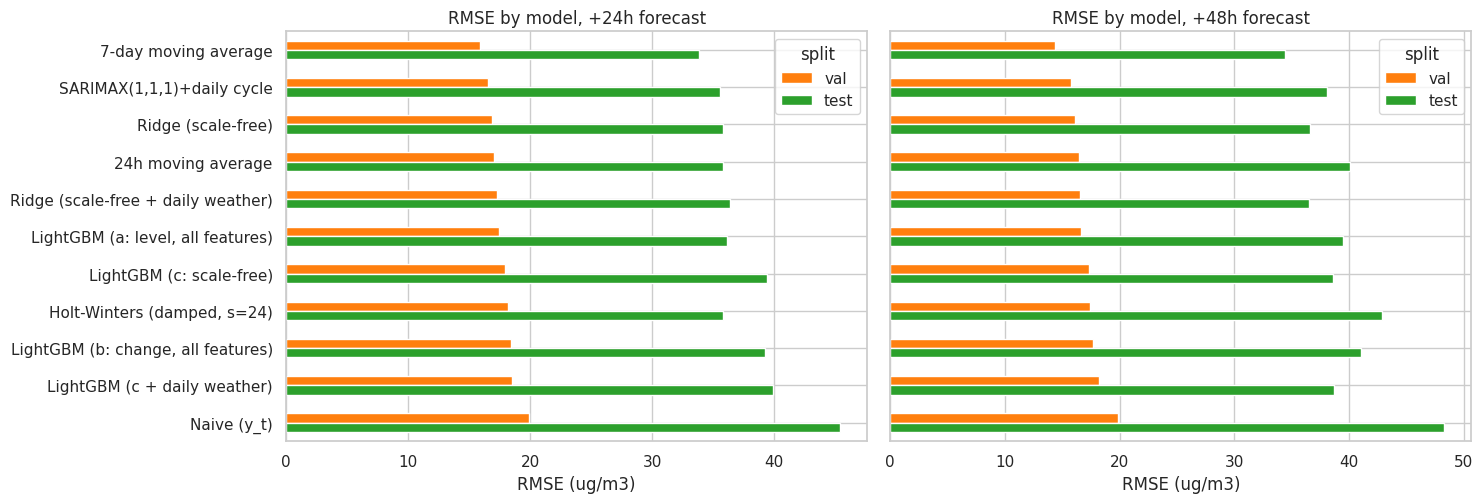

In [ ]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(15, 5.2), sharey=True)
for ax, h in zip(np.atleast_1d(axes), HORIZONS):
    d = res[res.horizon == f"+{h}h"].pivot(index="model", columns="split", values="RMSE")[["val", "test"]].sort_values("val")
    d.plot.barh(ax=ax, color=["tab:orange", "tab:green"]); ax.invert_yaxis()
    ax.set_title(f"RMSE by model, +{h}h forecast"); ax.set_xlabel("RMSE (ug/m3)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### What do the daily weather features add? (ablation)
Same model, same inputs, with and without the three daily-weather columns. A negative change means weather helped.

In [ ]:
pairs = [("LightGBM (c: scale-free)", "LightGBM (c + daily weather)"), ("Ridge (scale-free)", "Ridge (scale-free + daily weather)")]
rows = []
for a, b in pairs:
    for h in HORIZONS:
        for sp in ["val", "test"]:
            ra = res[(res.model == a) & (res.horizon == f"+{h}h") & (res.split == sp)]["RMSE"].iloc[0]
            rb = res[(res.model == b) & (res.horizon == f"+{h}h") & (res.split == sp)]["RMSE"].iloc[0]
            rows.append({"model": a.split(" (")[0], "horizon": f"+{h}h", "split": sp, "RMSE_without": ra, "RMSE_with_weather": rb, "change": rb - ra})
display(pd.DataFrame(rows).round(2).set_index(["model", "horizon", "split"]))

RMSE_without  RMSE_with_weather  change
model    horizon split                                         
LightGBM +24h    val           17.44              18.22    0.77
                 test          36.15              35.82   -0.33
         +48h    val           17.37              18.25    0.88
                 test          38.63              38.74    0.11
Ridge    +24h    val           16.88              16.99    0.12
                 test          35.81              35.79   -0.01
         +48h    val           16.10              16.56    0.46
                 test          36.64              36.50   -0.14

### How much can we trust the test numbers?
The test window is a few weeks long and consecutive hours are strongly correlated, so a plain RMSE is a noisy point estimate. A **moving-block bootstrap** (24 h blocks) resamples the test errors to give a rough 95% interval. Where intervals overlap, the ranking of models is not reliable.

In [ ]:
def block_ci(err, block=24, n_boot=400, seed=0):
    e2 = np.asarray(err, dtype=float) ** 2
    n = len(e2); nb = int(np.ceil(n / block)); rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_boot):
        starts = rng.integers(0, n - block + 1, size=nb)
        out.append(np.sqrt(np.concatenate([e2[s:s + block] for s in starts])[:n].mean()))
    return np.percentile(out, [2.5, 97.5])

rows = []
for h in HORIZONS:
    ix = split_idx(h, "test"); yt = actual(h, ix)
    for name, p in preds[h].items():
        err = (yt - p.loc[ix]).values
        lo, hi = block_ci(err)
        rows.append({"horizon": f"+{h}h", "model": name, "test_RMSE": np.sqrt((err ** 2).mean()), "CI95_low": lo, "CI95_high": hi})
ci = pd.DataFrame(rows).round(1)
display(ci.sort_values(["horizon", "test_RMSE"]).set_index(["horizon", "model"]))

test_RMSE  CI95_low  CI95_high
horizon model                                                             
+24h    7-day moving average                     33.8      23.1       46.1
        SARIMAX(1,1,1)+daily cycle               35.5      26.1       48.0
        LightGBM (c + daily weather)             35.8      23.2       49.6
        Ridge (scale-free)                       35.8      24.3       48.9
        Ridge (scale-free + daily weather)       35.8      24.5       48.9
        LightGBM (c: scale-free)                 36.1      23.7       49.7
        24h moving average                       36.4      27.4       48.7
        LightGBM (b: change, all features)       39.2      24.9       52.6
        Holt-Winters (damped, s=24)              39.4      27.9       51.7
        LightGBM (a: level, all features)        39.9      26.0       53.9
        Naive (y_t)                              45.4      31.1       60.2
+48h    7-day moving average                     34.4      24.4       47.7
        Ridge (scale-free + daily weather)       36.5      25.6       50.9
        Ridge (scale-free)                       36.6      25.6       51.1
        SARIMAX(1,1,1)+daily cycle               38.1      28.5       51.8
        LightGBM (c: scale-free)                 38.6      26.7       54.3
        LightGBM (c + daily weather)             38.7      25.7       54.1
        LightGBM (a: level, all features)        39.5      25.3       54.5
        24h moving average                       40.1      30.0       54.0
        LightGBM (b: change, all features)       41.1      27.8       55.6
        Holt-Winters (damped, s=24)              42.9      33.5       55.6
        Naive (y_t)                              48.3      37.0       61.6

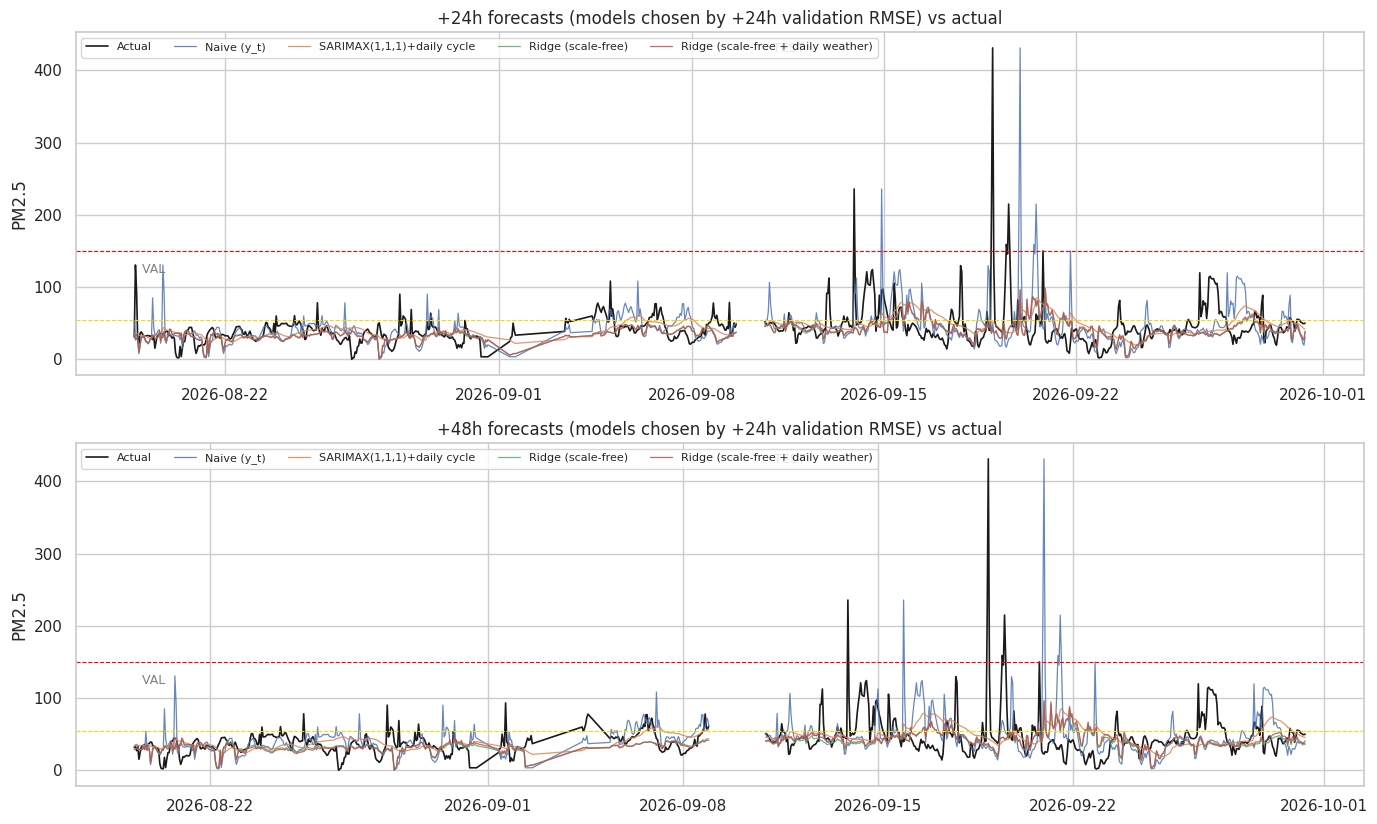

In [ ]:
# Forecast vs actual (x-axis = the time being forecast); val and test windows drawn separately
show_models = ["Naive (y_t)"] + list(res[(res.horizon == f"+{HORIZONS[0]}h") & (res.split == "val") & ~res.model.isin(["Naive (y_t)", "24h moving average", "7-day moving average"])]
                                      .sort_values("RMSE").model[:3])
fig, axes = plt.subplots(len(HORIZONS), 1, figsize=(14, 4.2 * len(HORIZONS)))
for ax, h in zip(np.atleast_1d(axes), HORIZONS):
    for k, sp in enumerate(["val", "test"]):
        ix = split_idx(h, sp); tt = ix + h * H
        ax.plot(tt, actual(h, ix).values, color="k", lw=1.2, label="Actual" if k == 0 else None)
        for j, name in enumerate(show_models):
            ax.plot(tt, preds[h][name].loc[ix].values, lw=0.9, alpha=0.85, color=f"C{j}", label=name if k == 0 else None)
        ax.text(tt[0], ax.get_ylim()[1] * 0.97, "  " + sp.upper(), va="top", fontsize=9, color="grey")
    ax.axhline(EVENT_THR, color="gold", ls="--", lw=0.8); ax.axhline(HIGH_THR, color="red", ls="--", lw=0.8)
    ax.set_title(f"+{h}h forecasts (models chosen by +{HORIZONS[0]}h validation RMSE) vs actual"); ax.set_ylabel("PM2.5")
    ax.legend(ncol=5, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

### Haze-event alerts
A forecast above the threshold counts as an alert, with no threshold tuning. First the NEA "Elevated" edge (55 ug/m3, the haze-event definition used here), then the "High" edge (150). Check `actual_events`: with few real events, precision and recall are only indicative.

In [ ]:
def alerts(h, sp, thr):
    ix = split_idx(h, sp); truth = actual(h, ix) > thr; out = []
    for name, p in preds[h].items():
        pr = p.loc[ix] > thr
        tp, fp, fn = int((pr & truth).sum()), int((pr & ~truth).sum()), int((~pr & truth).sum())
        out.append({"horizon": f"+{h}h", "split": sp, "model": name, "actual_events": int(truth.sum()), "TP": tp, "FP": fp, "FN": fn,
                    "precision": round(tp / (tp + fp), 2) if tp + fp else np.nan,
                    "recall": round(tp / (tp + fn), 2) if tp + fn else np.nan})
    return out

for thr in (EVENT_THR, HIGH_THR):
    print(f"Alerts at PM2.5 > {thr} ug/m3 (test set only shown; validation in the full table below)")
    tbl = pd.DataFrame([r for h in HORIZONS for sp in ["val", "test"] for r in alerts(h, sp, thr)])
    display(tbl[tbl.split == "test"].drop(columns="split").set_index(["horizon", "model"]))
    if thr == EVENT_THR:
        alert_tbl_val = tbl[tbl.split == "val"]

Alerts at PM2.5 > 55 ug/m3 (test set only shown; validation in the full table below)


actual_events  TP   FP   FN  precision  recall
horizon model                                                                             
+24h    Naive (y_t)                                   102  20   87   82       0.19    0.20
        24h moving average                            102  27   92   75       0.23    0.26
        7-day moving average                          102   6   77   96       0.07    0.06
        SARIMAX(1,1,1)+daily cycle                    102  28  104   74       0.21    0.27
        Holt-Winters (damped, s=24)                   102  30  106   72       0.22    0.29
        LightGBM (a: level, all features)             102   0    0  102        NaN    0.00
        LightGBM (b: change, all features)            102   4    5   98       0.44    0.04
        LightGBM (c: scale-free)                      102  11   43   91       0.20    0.11
        LightGBM (c + daily weather)                  102   9   32   93       0.22    0.09
        Ridge (scale-free)                            102  12   56   90       0.18    0.12
        Ridge (scale-free + daily weather)            102  13   61   89       0.18    0.13
+48h    Naive (y_t)                                   102  20   81   82       0.20    0.20
        24h moving average                            102   9  110   93       0.08    0.09
        7-day moving average                          102   7   76   95       0.08    0.07
        SARIMAX(1,1,1)+daily cycle                    102   8  122   94       0.06    0.08
        Holt-Winters (damped, s=24)                   102  26  101   76       0.20    0.25
        LightGBM (a: level, all features)             102   0    0  102        NaN    0.00
        LightGBM (b: change, all features)            102   1    9  101       0.10    0.01
        LightGBM (c: scale-free)                      102   6   48   96       0.11    0.06
        LightGBM (c + daily weather)                  102   2   33  100       0.06    0.02
        Ridge (scale-free)                            102   2   46  100       0.04    0.02
        Ridge (scale-free + daily weather)            102   2   50  100       0.04    0.02

Alerts at PM2.5 > 150 ug/m3 (test set only shown; validation in the full table below)


actual_events  TP  FP  FN  precision  recall
horizon model                                                                           
+24h    Naive (y_t)                                     6   0   6   6        0.0     0.0
        24h moving average                              6   0   0   6        NaN     0.0
        7-day moving average                            6   0   0   6        NaN     0.0
        SARIMAX(1,1,1)+daily cycle                      6   0   0   6        NaN     0.0
        Holt-Winters (damped, s=24)                     6   0   2   6        0.0     0.0
        LightGBM (a: level, all features)               6   0   0   6        NaN     0.0
        LightGBM (b: change, all features)              6   0   2   6        0.0     0.0
        LightGBM (c: scale-free)                        6   0   0   6        NaN     0.0
        LightGBM (c + daily weather)                    6   0   0   6        NaN     0.0
        Ridge (scale-free)                              6   0   0   6        NaN     0.0
        Ridge (scale-free + daily weather)              6   0   0   6        NaN     0.0
+48h    Naive (y_t)                                     6   0   6   6        0.0     0.0
        24h moving average                              6   0   0   6        NaN     0.0
        7-day moving average                            6   0   0   6        NaN     0.0
        SARIMAX(1,1,1)+daily cycle                      6   0   0   6        NaN     0.0
        Holt-Winters (damped, s=24)                     6   0   2   6        0.0     0.0
        LightGBM (a: level, all features)               6   0   0   6        NaN     0.0
        LightGBM (b: change, all features)              6   0   1   6        0.0     0.0
        LightGBM (c: scale-free)                        6   0   0   6        NaN     0.0
        LightGBM (c + daily weather)                    6   0   0   6        NaN     0.0
        Ridge (scale-free)                              6   0   0   6        NaN     0.0
        Ridge (scale-free + daily weather)              6   0   0   6        NaN     0.0

## Part 3 · 7. Shortlist for tuning (Phase 5)
The two strongest **non-baseline** models by mean validation RMSE across the two horizons. The test set plays no part in this choice.

In [ ]:
BASELINES = ("Naive (y_t)", "24h moving average", "7-day moving average")
CANDIDATES = [m for m in preds[HORIZONS[0]] if m not in BASELINES]
val_rank = (res[(res.split == "val") & res.model.isin(CANDIDATES)].pivot_table(index="model", columns="horizon", values="RMSE"))
val_rank["mean_val_RMSE"] = val_rank.mean(axis=1)
val_rank = val_rank.sort_values("mean_val_RMSE").round(2)
display(val_rank)
TOP2 = list(val_rank.index[:2])
print("Shortlisted for Phase 5 tuning:", TOP2)

horizon,+24h,+48h,mean_val_RMSE
model,,,
"SARIMAX(1,1,1)+daily cycle",16.54,15.77,16.16
Ridge (scale-free),16.88,16.10,16.49
Ridge (scale-free + daily weather),16.99,16.56,16.78
LightGBM (c: scale-free),17.44,17.37,17.40
"LightGBM (a: level, all features)",18.48,16.65,17.57
"Holt-Winters (damped, s=24)",17.92,17.41,17.67
"LightGBM (b: change, all features)",18.44,17.71,18.08
LightGBM (c + daily weather),18.22,18.25,18.23


Shortlisted for Phase 5 tuning: ['SARIMAX(1,1,1)+daily cycle', 'Ridge (scale-free)']


## Reading these results (Phase 4)

**What the numbers say**
- Every non-naive model beats the naive forecast (y_t) by roughly 8-29% RMSE, so some structure is learnable.
- **No candidate beats the 7-day moving average on the test set** (+24h RMSE 33.8 vs 35.5-39.7; +48h 34.4 vs 36.5-42.9). On validation the 7-day average is also best at +24h and +48h except that SARIMAX is close.
- The 95% block-bootstrap intervals of the top models overlap heavily (e.g. +24h: 23-50), so the **ranking between models is not statistically reliable**. We cannot claim one model is better than another.
- Daily weather (rain, wind from Marina Barrage) does **not** give a consistent gain: RMSE changes are within about +/-0.9 µg/m3 and flip sign between validation and test.
- **Spike alerts are weak.** At >55 µg/m3 the best test recall is about 0.29 with precision about 0.22 (Holt-Winters, +24h); at >150 µg/m3 no model catches any of the 6 test hours. LightGBM (a) predicts no events at all because trees cannot go above values seen in training.

**Why**
- Training period (Apr-mid Aug) is calm (mean 20 µg/m3) while validation/test are hazier (38 / 49). Models learn "calm" behaviour and shrink toward it.
- Only 3 training hours exceed 150 µg/m3; learning spikes from so few examples is not possible.
- A sensor-only, single-site view sees a plume only after it arrives. Without upwind data (fire hotspots, wind direction) a 24-48 h warning is mostly guesswork.

**Shortlist for Phase 5 (by mean validation RMSE):** SARIMAX(1,1,1)+daily cycle and Ridge (scale-free). The shortlist is chosen on validation only; the 7-day moving average remains the benchmark to beat.

## Limitations (read before using any number above)

**Data**
1. **One sensor** (Marine Terrace, low-cost AirGradient, not calibrated against NEA reference monitors; humidity can bias optical PM2.5). Results describe this location only. No spatial features are possible.
2. **Coverage is 9 Apr - 30 Sep 2026.** The October haze peak is not in the data, so the most relevant episodes for the project theme are missing.
3. **Gaps:** one 17-day outage (28 Apr - 15 May, 407 h), plus five ~24 h gaps at each month boundary (exports ended at 08:00 UTC on the last day) and several short gaps. Short gaps (<=6 h) are forward-filled; longer ones stay missing. The month-boundary gaps can be recovered by re-exporting with the end date set to the 1st of the next month.
4. 121 zero/invalid sensor values were set to missing (24 exact-zero PM2.5 readings look like dropouts).
5. **Weather is daily only** (Marina Barrage). No wind direction, no hourly resolution, and all three temperature columns are empty. Because a day's summary is only known after the day ends, weather features use days up to D-1 and cannot describe today's rain or wind.
6. No fire-hotspot, satellite or upwind-station data, which are the real drivers of transboundary haze.

**Modelling**
7. **Regime shift:** train mean 20, validation 38, test 49 µg/m3. Metrics on validation and test are not comparable to each other.
8. **Very few spike hours:** 10 hours above 150 in the whole file (3 train, 0 validation, 6 test, and 5 of those 6 test hours belong to a single day, 18-19 Sep). Spike metrics are anecdotal.
9. Hourly rows are strongly autocorrelated, so the effective sample size is far smaller than the row count; bootstrap uses 24 h blocks to account for this, but intervals are still approximate.
10. Chronological 70/15/15 split with purging (rows whose target falls in the next period are dropped). No month feature is used, since the training period contains no October-like months.
11. Classical models (SARIMAX, Holt-Winters) use data after the 17-day outage with up to 30 h of interpolation; parameters are fitted once on train and not refit per origin.
12. The scale-free features and log-ratio target were designed after seeing validation behaviour, so validation scores are slightly optimistic for those variants.
13. Weather correlations (e.g. wind vs next-day PM2.5, about +0.24) are associations on a small sample and are not causal.
14. NEA health advisories use 24-h PSI; this notebook uses the 1-hour PM2.5 bands only.

**Next (Part 4):** Phase 5 tuning of the two shortlisted models with expanding-window `TimeSeriesSplit` (default vs tuned), then Phase 6 interpretation (importance/SHAP, recommendations) and the Phase 7 package.